# M02a · Intégrales et densités — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/m02a_integrales_densites/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | M02a.1 à M02a.10, M02a.13 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | M02a.16 | Rectangles et trapèzes · `riemann_sum`, `trapezoid` | 🔨 | ★ | 20 |
|  | M02a.17 | La méthode de Simpson · `simpson` | 🔨 | ★★ | 15 |
|  | M02a.18 | De la densité à la fonction de répartition, puis au quantile par dichotomie · `cdf_from_pdf`, `quantile` | 🔨 | ★★ | 25 |
|  | M02a.19 | Vérifier avec `scipy.integrate.quad` et SymPy | 📦 | ★ | 15 |
| B | M02a.20 | Prédire : le pas divisé par 2, l'erreur divisée par combien ? | 🔮 | ★ | 10 |
|  | M02a.21 | L'intégrale de Gauss par le calcul : la borne qui s'éloigne | 🔬 | ★★ | 20 |
|  | M02a.22 | L'aire qui se remplit : la courbe, les rectangles et la primitive | 🎨 | ★ | 20 |
| C | M02a.23 | Chasse à l'erreur : bornes inversées, primitive fausse, aire négative | 🐛 | ★ | 15 |
|  | M02a.24 | Vérifier une primitive avec SymPy : dériver le résultat | 🛠️ | ★ | 10 |
|  | M02a.25 | Défi : la meilleure précision avec dix évaluations de la fonction | 🏆 | ★★★ | 30 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : sommes de Riemann, primitives, intégrales et aires, intégration par parties et changement de variable, intégrales impropres, trapèzes et Simpson, densités, probabilités, fonctions de répartition et quantiles, AUC.
- Écrire les cinq fonctions de `mymath/integrate.py` et les tester, puis comparer avec SciPy et SymPy.
- Prédire l'effet d'un pas divisé par 2, approcher l'intégrale de Gauss, dessiner l'aire qui se remplit, chasser des erreurs de calcul intégral, vérifier une primitive, relever le défi des dix évaluations.

**Rappel express.** $\int_a^b f = F(b) - F(a)$ avec $F' = f$. $h = \frac{b - a}{n}$ ; trapèzes : $h\big(\frac{f_0}{2} + f_1 + \cdots + \frac{f_n}{2}\big)$ ; Simpson ($n$ pair) : $\frac{h}{3}(f_0 + 4f_1 + 2f_2 + \cdots + 4f_{n-1} + f_n)$. Densité : $f \ge 0$, $\int f = 1$, $P(a \le X \le b) = \int_a^b f$ ; $F(x) = P(X \le x)$ ; quantile $q_p$ : $F(q_p) = p$.

## Partie 0 · Vérifier tes exercices papier (✏️ M02a.1 à M02a.10, 🔗 M02a.13)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question ;
- une fraction irréductible entre guillemets, `"5/9"` ;
- une valeur exacte entre guillemets, avec `sqrt`, `pi`, `exp` ou `ln`, `"sqrt(5)/3"` ;
- une expression en $x$ entre guillemets, avec `**` pour les puissances et des parenthèses autour d'un dénominateur ou d'un exposant, `"x**4/4 - 3/(2*x)"`, `"exp(3*x)"` (une primitive se vérifie à une constante près) ;
- une liste `[-1.25, 1]`, un intervalle `"]-oo ; -7]"`, une lettre `"C"`, ou `True` / `False`.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly from the statements
import math
from fractions import Fraction

import sympy as sp

**Ex M02a.1 — Sommes de Riemann à la main : rectangles à gauche, à droite, au milieu**

In [3]:
wbm.record("M02a.1a", (2 - 0) / 4, decimals=1, mistakes={"h = (b − a)/n : la longueur de l'intervalle divisée par le nombre de rectangles": {2, 0.2, 4}})
wbm.record("M02a.1b", 0.5 * (8 + 3.375 + 1 + 0.125), decimals=2, mistakes={"à gauche : la hauteur se lit au début de chaque intervalle, x de 0 à 1,5": 2.25, "multiplie la somme des hauteurs par la largeur h des rectangles": 12.5})
wbm.record("M02a.1c", 0.5 * (3.375 + 1 + 0.125 + 0), decimals=2, mistakes={"à droite : la hauteur se lit à la fin de chaque intervalle, x de 0,5 à 2": 6.25, "multiplie la somme des hauteurs par la largeur h des rectangles": 4.5})
wbm.record("M02a.1d", 0.5 * (1.75 ** 3 + 1.25 ** 3 + 0.75 ** 3 + 0.25 ** 3), decimals=3, mistakes={"multiplie la somme des hauteurs par la largeur h des rectangles": 7.75, "c'est l'aire exacte ; la question demande la somme de Riemann au milieu, qui l'approche": 4, "au milieu : les hauteurs se lisent aux milieux des intervalles, en 0,25, 0,75, 1,25 et 1,75": 4.25})
wbm.record("M02a.1e", 4, mistakes={"L₄ − R₄, dans cet ordre : f est décroissante, la somme à gauche est la plus grande": -4, "L₄ et R₄ sont des aires : la différence des hauteurs se multiplie par la largeur h": 8})
wbm.record("M02a.1f", 0.25 * sum((2 - 0.25 * i) ** 3 for i in range(8)), decimals=4, mistakes={"multiplie la somme des huit hauteurs par la largeur h des rectangles": 20.25, "avec n = 8, le pas vaut 2/8 : les hauteurs se lisent en 0 ; 0,25 ; … ; 1,75": 6.25, "c'est R₈ ; L₈ lit les hauteurs au début de chaque intervalle, de 0 à 1,75": 3.0625})
wbm.record("M02a.1g", 160, mistakes={"L_n − R_n = h (f(0) − f(2)), avec h = 2/n : la longueur de l'intervalle compte": 80, "le plus petit entier n qui vérifie L_n − R_n ≤ 0,1 (inégalité large) : vérifie aussi l'entier juste en dessous": 161, "l'inégalité est L_n − R_n ≤ 0,1 : avec ce n, l'écart est encore trop grand": 159})
wbm.record("M02a.1h", True, mistakes={"f décroît : chaque rectangle à gauche dépasse la courbe, chaque rectangle à droite est dessous": False})

WBM_ANSWER {"alt_coarse": ["82edfbf9fa829170c0a965a625b9f7ce6e3a30383f6835b4d9b8672c8e39b641"], "decimals": 1, "hash": "4d5e176ffc06f989a1e00fb5e0eb3b52c1d845989c3033f389dcf5457c2ba2e3", "hash_coarse": "01817169560ff7b7ae0b986406647b41ba49ab5474b7e830c3f531de2f5e53cb", "id": "M02a.1a", "kind": "float", "magnitude": -1, "mistakes": {"8c6948bf81e9ff8ce86b63bc4ffb0d8634f173fbef457ac313eb6637bd692a12": "h = (b − a)/n : la longueur de l'intervalle divisée par le nombre de rectangles", "cf3cdc510c948a02b156bff8a2634eea98eebe0e31f78b9750f5bfe5c5f5178c": "h = (b − a)/n : la longueur de l'intervalle divisée par le nombre de rectangles", "db377d282a89734c3c1a384b2cbbb98fe189901bf19262e1bfcb71115fe1eb07": "h = (b − a)/n : la longueur de l'intervalle divisée par le nombre de rectangles"}, "sign": 1}
📝 Ex M02a.1a : réponse enregistrée (float, 1 décimale).
WBM_ANSWER {"alt_coarse": ["b1386a5caa22c79036929b00151ca86a8b1e91053abd6aeb4ffc7fca5d849704"], "coarse_any": {"0": ["f099d4b5d6e2d776bd2a49b5e26

**Ex M02a.2 — Primitives usuelles**

In [4]:
wbm.record("M02a.2a", "2*x**3 - 2*x**2 + 5*x", kind="expr", variables=("x",), up_to_constant=True, mistakes={"c'est la dérivée de la fonction : une primitive F vérifie F′ = f": "12*x - 4", "xⁿ a pour primitive xⁿ⁺¹/(n + 1) : divise par le nouvel exposant": "6*x**3 - 4*x**2 + 5*x"})
wbm.record("M02a.2b", "-1/(2*x**2)", kind="expr", variables=("x",), up_to_constant=True, mistakes={"x⁻³ a pour primitive x⁻²/(−2) : le signe vient de la division par −2": "1/(2*x**2)", "divise par le nouvel exposant, −2, pas par l'ancien": "-1/(3*x**2)", "c'est la dérivée de 1/x³ ; une primitive se dérive en 1/x³": "-3/x**4"})
wbm.record("M02a.2c", "2*x**(3/2)/3", kind="expr", variables=("x",), up_to_constant=True, mistakes={"√x = x^(1/2) a pour primitive x^(3/2) divisée par 3/2, donc multipliée par 2/3": "3*x**(3/2)/2", "c'est la dérivée de √x ; une primitive se dérive en √x": "1/(2*sqrt(x))"})
wbm.record("M02a.2d", "exp(3*x)/3", kind="expr", variables=("x",), up_to_constant=True, mistakes={"la dérivée de e^(3x) vaut 3 e^(3x) : divise par 3": "exp(3*x)", "divise par 3, ne multiplie pas : dérive ta réponse pour vérifier": "3*exp(3*x)"})
wbm.record("M02a.2e", "log(2*x + 1)/2", kind="expr", variables=("x",), up_to_constant=True, mistakes={"la dérivée de ln(2x + 1) vaut 2/(2x + 1) : divise par 2": "log(2*x + 1)"})
wbm.record("M02a.2f", "sin(2*x)/2", kind="expr", variables=("x",), up_to_constant=True, mistakes={"la dérivée de sin vaut cos : une primitive de cos est sin, sans signe moins": "-sin(2*x)/2", "la dérivée de sin(2x) vaut 2 cos(2x) : divise par 2": "sin(2*x)"})
wbm.record("M02a.2g", "x**3 + x - 2", kind="expr", variables=("x",), mistakes={"c'est bien une primitive, mais pas celle qui vaut 0 en x = 1 : choisis la constante": "x**3 + x", "la constante se choisit pour que F(1) = 0 : vérifie son signe": "x**3 + x + 2"})
wbm.record("M02a.2h", "4*log(x) - exp(-x)", kind="expr", variables=("x",), up_to_constant=True, mistakes={"une primitive de e^(−x) est −e^(−x) : dérive-la pour vérifier le signe": "4*log(x) + exp(-x)"})

WBM_ANSWER {"hash": "6fe70f30278a54918c97f6bc5aa37799aa1dde20889d409b96250bc5cdb0467a", "id": "M02a.2a", "kind": "expr", "mistakes": {"3e6259bc1d0e728493ec579854b2fa81cf802d146400c8c106eba5a5ae767ae6": "xⁿ a pour primitive xⁿ⁺¹/(n + 1) : divise par le nouvel exposant", "66fefb011a2fb9e40a61280c374cc5d6a0d6788aced2c2fe59a2aeea64191ab9": "c'est la dérivée de la fonction : une primitive F vérifie F′ = f"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"], ["-7/3"]], "up_to_constant": true, "variables": ["x"]}
📝 Ex M02a.2a : réponse enregistrée (expr).
WBM_ANSWER {"hash": "adc01b61d601fd2aaab4b073a0d3eee5e4585a1b8f9943dd34c24823930799c9", "id": "M02a.2b", "kind": "expr", "mistakes": {"504f90e82bb70fa8168622ac60dc57320b0c9b231c73359e4338824c343e99e6": "c'est la dérivée de 1/x³ ; une primitive se dérive en 1/x³", "cba8e77c1bf03e9908f5d73029fd46361e2ffa83b1fd86cf763fdc11b3dfc1f0": "divise par le nouvel exposant, −2, pas par l'ancien", "fbefcbcdc242365b2c84b1a2a95b726f2d51fdb86a37b2d196

**Ex M02a.3 — Intégrales et aires : le signe, l'aire entre deux courbes**

In [5]:
wbm.record("M02a.3a", (4 ** 2 - 4) - (1 ** 2 - 1), mistakes={"une primitive de 2x − 1 est x² − x : n'oublie pas le −x": 15, "[F(x)] de 1 à 4 vaut F(4) − F(1), pas F(1) − F(4)": -12})
wbm.record("M02a.3b", 3 - 1, mistakes={"F(b) − F(a) : n'oublie pas de retrancher e⁰ = 1": 3})
wbm.record("M02a.3c", 2 * 3, mistakes={"une primitive de 2/x est 2 ln x : garde le facteur 2": 3})
wbm.record("M02a.3d", 0, mistakes={"c'est l'aire géométrique ; l'intégrale compte négativement la partie sous l'axe": 3})
wbm.record("M02a.3e", Fraction(8, 3), kind="fraction", simplified=True, mistakes={"c'est l'intégrale ; l'aire compte positivement la partie sous l'axe : coupe là où la fonction change de signe": "0", "x² − 2x est sous l'axe sur [0 ; 2] et au-dessus sur [−1 ; 0] : additionne les valeurs absolues des deux morceaux": "4/3"})
wbm.record("M02a.3f", [0, 2], mistakes={"résous 2x = x², soit x² − 2x = 0 : deux solutions": [2]})
wbm.record("M02a.3g", Fraction(4, 3), kind="fraction", simplified=True, mistakes={"la courbe du haut moins celle du bas : sur [0 ; 2], 2x est au-dessus de x²": "-4/3"})
wbm.record("M02a.3h", Fraction(1, 2), kind="fraction", simplified=True, mistakes={"une primitive de sin est −cos, pas cos : dérive pour vérifier": "-1/2", "[−cos x] de 0 à π/3 : attention aux deux signes moins de −cos(π/3) − (−cos 0)": "-3/2", "F(π/3) − F(0) avec F = −cos : calcule chaque terme avec son signe, puis leur différence": "3/2"})

WBM_ANSWER {"hash": "5428b75dfee8d5e030039e9c176983ddc171a09327219e2762966d9f24f35726", "id": "M02a.3a", "kind": "int", "magnitude": 1, "mistakes": {"bed39a2e2e4ac2944f248fd2fe2c3d37fb7b64abcea3ce515468a1b2f1a1dc80": "[F(x)] de 1 à 4 vaut F(4) − F(1), pas F(1) − F(4)", "bffedb63828b132d3c4dc1ddf7343506ce2c15f64039f5d9f4f9d4415d337f71": "une primitive de 2x − 1 est x² − x : n'oublie pas le −x"}, "sign": 1}
📝 Ex M02a.3a : réponse enregistrée (int).
WBM_ANSWER {"hash": "fa93b4b711eefb0876f1052db4349fb39945c1c13480e15a5db458fde7369912", "id": "M02a.3b", "kind": "int", "magnitude": 0, "mistakes": {"489454658027d57126eedcedb17658fe59172b7e504dd34b4cd6699b39b65531": "F(b) − F(a) : n'oublie pas de retrancher e⁰ = 1"}, "sign": 1}
📝 Ex M02a.3b : réponse enregistrée (int).
WBM_ANSWER {"hash": "a2c4ccf59e6b2bc8479b858af0c2178953b06842caa59528944ef343078ec560", "id": "M02a.3c", "kind": "int", "magnitude": 0, "mistakes": {"d643f4f5336c3004705ec140287b990affdd3de4379587cf7eddf715f0fce824": "une primi

**Ex M02a.4 — Intégration par parties**

In [6]:
wbm.record("M02a.4a", 1, choices=[1, 2], mistakes={"on dérive le facteur qui se simplifie en dérivant ; l'autre doit s'intégrer facilement": 2})
wbm.record("M02a.4b", (math.exp(2) + 1) / 4, decimals=4, mistakes={"v est une primitive de e^(2x) : e^(2x)/2, pas e^(2x)": (math.exp(2) + 1) / 2, "[uv] − ∫ u′v : n'oublie pas de retrancher la seconde intégrale": math.exp(2) / 2})
wbm.record("M02a.4c", "x*sin(x) + cos(x)", kind="expr", variables=("x",), up_to_constant=True, mistakes={"[uv] − ∫ u′v avec v = sin x : une primitive de sin est −cos, d'où un signe": "x*sin(x) - cos(x)"})
wbm.record("M02a.4d", 1, mistakes={"u = ln x, v′ = 1 : [x ln x] de 1 à e, moins ∫ 1 dx": 3, "F(e) − F(1) : n'oublie pas de calculer la primitive en 1, puis de la retrancher": 0})
wbm.record("M02a.4e", "x**2*log(x)/2 - x**2/4", kind="expr", variables=("x",), up_to_constant=True, mistakes={"[uv] − ∫ u′v avec u = ln x et v = x²/2 : la seconde intégrale se retranche": "x**2*log(x)/2 + x**2/4", "v est une primitive de x : x²/2, pas x²": "x**2*log(x) - x**2/2"})
wbm.record("M02a.4f", math.e - 2, decimals=4, mistakes={"la dérivée de x² vaut 2x : le facteur 2 reste devant la seconde intégrale": math.e - 1, "la seconde intégration par parties se retranche aussi : attention aux signes": 2 - 3 * math.e})

WBM_ANSWER {"choices": ["1", "2"], "hash": "879c4cda5674edc81e1aafd1d1297f018021312871a7ccec0e62bcae5d0e604c", "id": "M02a.4a", "kind": "int", "magnitude": 0, "mistakes": {"926135024a03d1058f8fdcde918e8034a8a55f378ecabdc8cfbcd33b0a482841": "on dérive le facteur qui se simplifie en dérivant ; l'autre doit s'intégrer facilement"}, "sign": 1}
📝 Ex M02a.4a : réponse enregistrée (int).
WBM_ANSWER {"coarse_any": {"0": ["283d56c107d6ad8166b30213923faffddc235ca4ab324ef6d5121d8a192475cc"]}, "coarser": {"1": ["a6d5d6e9e0d3889c16ba002bb9a0b9c364a55e4e530cea38c7e2e66810faf8a8"], "2": ["e46f9891656dc2f6d5f8836b1326a42aa53c97863e6615a7aec0cee84d58149b"]}, "decimals": 4, "hash": "d7870b9ca691a330c9af4cea916a082f6cf4277529221591617034bcfd8afba6", "hash_coarse": "ab470564c91a17098ebedc4e870fe14f15a98404decbafcb7b29750d8cc0ebed", "id": "M02a.4b", "kind": "float", "magnitude": 0, "mistakes": {"33509f4b355540ff4c55e54936fee38b986e82decb28a50d0fc8b6a6d1d863bc": "[uv] − ∫ u′v : n'oublie pas de retrancher la

WBM_ANSWER {"hash": "81c7b9750a3e270a0d612dcdb364d0394a36369cded2e0d7681b0ba9c9880e2d", "id": "M02a.4e", "kind": "expr", "mistakes": {"1bed1130ef29eaed17d002af89027d8ac09734b0587e81f288b065fd2f55de8f": "[uv] − ∫ u′v avec u = ln x et v = x²/2 : la seconde intégrale se retranche", "534c767cecb220a241f5c35858b0ead2c983e5fcc0231ee2d9c2cf05ffc26a8d": "v est une primitive de x : x²/2, pas x²"}, "points": [["1/3"], ["5/7"], ["6/5"], ["9/4"], ["3/11"], ["13/6"]], "up_to_constant": true, "variables": ["x"]}
📝 Ex M02a.4e : réponse enregistrée (expr).
WBM_ANSWER {"coarse_any": {"0": ["51df9256e95311eb8195ffb8ff7891be628f03cb37687963b5761ebf814abd5d"], "1": ["18ac837b78215a1709077bf264f25fde851f4b5535abe8889942a4b284680113"]}, "coarser": {"2": ["6c6e815031dee3e1476321c5743540aaed245561ecf9ea18546b490484e5867a"]}, "decimals": 4, "hash": "54bb636cb3ff3a35391cdc4f17b98f09126e733cac80d301f8c3b272e01893ca", "hash_coarse": "14a354fa6b168f3b49e3ca81edd98b1685014ccbb905934b84f66ca6cabdf84b", "id": "M02a.4

**Ex M02a.5 — Changement de variable**

In [7]:
wbm.record("M02a.5a", [3, 5], mistakes={"quand x va de 0 à 1, u = 2x + 3 va de u(0) à u(1) : change les bornes": [0, 1]})
wbm.record("M02a.5b", Fraction(31, 5), kind="fraction", simplified=True, mistakes={"u = x³ + 1 va de 1 à 2 : change les bornes avec la variable": "1/5", "la borne du bas vaut u(0) = 1 : F(2) − F(1)": "32/5"})
wbm.record("M02a.5c", "log(x**2 + 4)/2", kind="expr", variables=("x",), up_to_constant=True, mistakes={"u = x² + 4 donne du = 2x dx : il reste un facteur 1/2": "log(x**2 + 4)"})
wbm.record("M02a.5d", (math.exp(3) - math.e) / 2, decimals=4, mistakes={"u = 2x + 1 donne du = 2 dx : divise par 2": math.exp(3) - math.e, "u = 2x + 1 va de 1 à 3 : change les bornes": (math.e - 1) / 2})
wbm.record("M02a.5e", (1 - math.exp(-4)) / 2, decimals=4, mistakes={"u = x² va de 0 à 4 : change les bornes": (1 - math.exp(-2)) / 2, "u = x² donne du = 2x dx : il reste un facteur 1/2": 1 - math.exp(-4)})
wbm.record("M02a.5f", Fraction(1, 3), kind="fraction", simplified=True, mistakes={"u = ln x va de ln 1 = 0 à ln e = 1 : change les bornes": "2/3"})

WBM_ANSWER {"decimals": 0, "element_hashes": ["478ced2333a7b94702e32b4978260e3f07bc65226cc381713af9f9b4bb030b5a", "8440f1beb52e24c60d56d21296e1fb3d0be5dd64cfe094a8704486a57863e6bd"], "hash": "c9e9630d6440295e6ceff3c28dbbc2e7da88adbfc0becd5ed7a10d89b691a768", "id": "M02a.5a", "integer": true, "kind": "array", "mistakes": {"2aec6b0345d319fe02b58c26d8151799a2ac4980dfa73b97fe28c59578ca5322": "quand x va de 0 à 1, u = 2x + 3 va de u(0) à u(1) : change les bornes"}, "shape": [2]}
📝 Ex M02a.5a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"hash": "7c5a69f30147e1004c2c41840bbe99d651bc660dbbc75d9ac8537d543a77cb37", "id": "M02a.5b", "kind": "fraction", "mistakes": {"50a53784c3413fff784942419f2b94107d66ab5f483ecdcfd47ab9a092807973": "u = x³ + 1 va de 1 à 2 : change les bornes avec la variable", "50c7732b31f73df0f9fa78c255c7626c669451d05a6046337255f0dd19588bb7": "la borne du bas vaut u(0) = 1 : F(2) − F(1)"}, "sign": 1, "simplified": true}
📝 Ex M02a.5b : réponse enregistrée (fraction).


WBM_ANSWER {"hash": "6a05c428630fe9a6831df26ac5a95120c9b8090a10b1173dc66cf895ec8b8133", "id": "M02a.5c", "kind": "expr", "mistakes": {"54ce3087ec1448a29e9b549787c557d1ec31e631136e534005669c55172b5b16": "u = x² + 4 donne du = 2x dx : il reste un facteur 1/2"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"], ["-7/3"]], "up_to_constant": true, "variables": ["x"]}
📝 Ex M02a.5c : réponse enregistrée (expr).
WBM_ANSWER {"coarse_any": {"0": ["2735c98daad625000d47d4594f28be6f26e27d8bc5fc9e6528672e8b1882677f"]}, "coarser": {"1": ["3cfe4844d97b7a3ae6e889d6c04f857fc8bf5a551467b525b1654c59791ab8b1"], "2": ["d704b82b356bfaf0b2e4d34414bd82175241803297958013ea69de61ce386f56"]}, "decimals": 4, "hash": "94c02c0c33a10293dcc156b6340a20fb4a10c1bbc10b5d5cc3e9e6c5ff2c65a1", "hash_coarse": "6308e7f1b85ebc7970721c1c1216dc25e0b15c73d7755e9f8d1d9ef4e4a0dcbd", "id": "M02a.5d", "kind": "float", "magnitude": 0, "mistakes": {"ae58c592383332146e2dfce56faf0de9982c7e3504b9c8bbba04f68070efc318": "u = 2x + 1 do

**Ex M02a.6 — Intégrales impropres : converge, diverge, valeur**

In [8]:
wbm.record("M02a.6a", Fraction(1, 3), kind="fraction", simplified=True, mistakes={"[−1/x] de 3 à +∞ : la limite en +∞ vaut 0, moins la valeur en 3": "-1/3"})
wbm.record("M02a.6b", 3)
wbm.record("M02a.6c", 4, mistakes={"une primitive de x^(−1/2) est 2√x : [2√x] de 0 à 4": 2})
wbm.record("M02a.6d", False, mistakes={"∫ de 1 à +∞ de 1/xᵖ converge seulement si p > 1 ; ici p = 0,9": True})
wbm.record("M02a.6e", Fraction(1, 2), kind="fraction", simplified=True, mistakes={"[e^(2x)/2] de −∞ à 0 : la valeur en 0, moins la limite en −∞, qui vaut 0": "-1/2"})
wbm.record("M02a.6f", "]1 ; +oo[", kind="interval", mistakes={"pour p = 1, ∫ de 1 à b de dx/x vaut ln b, qui tend vers +∞ : 1 est exclu": "[1 ; +oo[", "c'est la règle de ∫ de 0 à 1 ; vers +∞, il faut décroître assez vite": "]-oo ; 1["})
wbm.record("M02a.6g", Fraction(1, 4), kind="fraction", simplified=True, mistakes={"x⁻⁵ a pour primitive x⁻⁴/(−4) : on divise par le nouvel exposant": "1/5", "[x⁻⁴/(−4)] de 1 à +∞ : la limite en +∞ vaut 0, moins la valeur en 1": "-1/4"})
wbm.record("M02a.6h", sp.sqrt(sp.pi) / 2, kind="exact", mistakes={"e^(−x²) est paire : de 0 à +∞, on a la moitié de l'intégrale de Gauss": "sqrt(pi)"})

WBM_ANSWER {"hash": "64263528244e06ccaada3e6e6508247ffa232d32180478d11f1685bffe085b08", "id": "M02a.6a", "kind": "fraction", "mistakes": {"df54d043873c57aa61f130a45bf3525e0d21c07acc49fb48048bd764f3a73d67": "[−1/x] de 3 à +∞ : la limite en +∞ vaut 0, moins la valeur en 3"}, "sign": 1, "simplified": true}
📝 Ex M02a.6a : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "b947c9f2eb02cbffe697a31ee4ebbfa070dc0a52dee4ac4589c42dec86eb65a4", "id": "M02a.6b", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex M02a.6b : réponse enregistrée (int).
WBM_ANSWER {"hash": "2943a1dd655ef8ee4840645c7970d865d007ec31c520f9c981e3dd805cb9b33f", "id": "M02a.6c", "kind": "int", "magnitude": 0, "mistakes": {"4c7fe2d1d8269d10ff8bc8d5ea4b850da5cadbff637873ce002e8c6886586579": "une primitive de x^(−1/2) est 2√x : [2√x] de 0 à 4"}, "sign": 1}
📝 Ex M02a.6c : réponse enregistrée (int).
WBM_ANSWER {"hash": "2b85c52abcd73eed3f28878bed133bbd7bfe94ace0f240e7c3b37eb5cd045080", "id": "M02a.6d", "kind": "bool", "mistakes": {

**Ex M02a.7 — Trapèzes et Simpson à la main, et leurs erreurs**

In [9]:
wbm.record("M02a.7a", 0.5 * (4 / 2 + 3.2 + 2 / 2), decimals=1, mistakes={"les deux extrémités comptent pour moitié dans la méthode des trapèzes": 4.6})
wbm.record("M02a.7b", Fraction(47, 15), kind="fraction", simplified=True, mistakes={"Simpson : (h/3) × (f(0) + 4 f(0,5) + f(1)), avec h = 0,5": "47/5"})
wbm.record("M02a.7c", 0.25 * (4 / 2 + 4 / 1.0625 + 3.2 + 4 / 1.5625 + 2 / 2), decimals=4, mistakes={"les deux extrémités comptent pour moitié dans la méthode des trapèzes": 0.25 * (4 + 4 / 1.0625 + 3.2 + 4 / 1.5625 + 2)})
wbm.record("M02a.7d", abs(3.1 - math.pi), decimals=4, mistakes={"l'erreur est un écart, positif : |T₂ − π|": 3.1 - math.pi})
wbm.record("M02a.7e", abs(3.1 - math.pi) / abs(0.25 * (4 / 2 + 4 / 1.0625 + 3.2 + 4 / 1.5625 + 2 / 2) - math.pi), decimals=1, mistakes={"l'erreur de T₂ divisée par celle de T₄, dans cet ordre": 0.2504})
wbm.record("M02a.7f", 0.25 / 3 * (4 + 4 * 4 / 1.0625 + 2 * 3.2 + 4 * 4 / 1.5625 + 2), decimals=5, mistakes={"les poids de Simpson : 1, 4, 2, 4, 1, le tout multiplié par h/3": 0.25 / 3 * (4 + 2 * 4 / 1.0625 + 4 * 3.2 + 2 * 4 / 1.5625 + 2)})
wbm.record("M02a.7g", 5, mistakes={"Simpson avec n intervalles utilise les n + 1 points x₀, …, xₙ": 4})
wbm.record("M02a.7h", True, mistakes={"sur chaque intervalle, le segment des trapèzes suit exactement une droite": False})

WBM_ANSWER {"decimals": 1, "hash": "9ffc2b74163e95d6cf447ac0b483a2b0701e8fd7ce4d73b5548d685c0be87c96", "hash_coarse": "64002dcc2db8f0442c35c2fb1f341f1a2d91f76331756b48a5f1fae5b9cfe78a", "id": "M02a.7a", "kind": "float", "magnitude": 0, "mistakes": {"01ee7fefd35f0e040c39027168e06f5080029a29cddfa5e90a4f9d2abf9ee0c4": "les deux extrémités comptent pour moitié dans la méthode des trapèzes"}, "sign": 1}
📝 Ex M02a.7a : réponse enregistrée (float, 1 décimale).
WBM_ANSWER {"hash": "6ecd1050cf0fbf1392554d408f0923e7118a402645a20684e862d798c3afa706", "id": "M02a.7b", "kind": "fraction", "mistakes": {"2054181535728bd80fbb7daca283a2e08b5ddeb026f400f27ce6df72492838fd": "Simpson : (h/3) × (f(0) + 4 f(0,5) + f(1)), avec h = 0,5"}, "sign": 1, "simplified": true}
📝 Ex M02a.7b : réponse enregistrée (fraction).
WBM_ANSWER {"coarse_any": {"0": ["e22c23717e89292e21839821d847660dd487cd43923c62675f00f99c67c6889b"]}, "coarser": {"1": ["f1e938dfe837b7b4be5eb00d1b5bb82496075207a38dbd37ad166c9251d7af9f"], "2": ["

**Ex M02a.8 — Vérifier qu'une fonction est une densité, trouver sa constante**

In [10]:
wbm.record("M02a.8a", Fraction(1, 8), kind="fraction", simplified=True, mistakes={"c × (l'intégrale de x de 0 à 4) = 1 : c est l'inverse de cette intégrale": "8", "une primitive de x est x²/2 : ∫ de 0 à 4 de x dx vaut 4²/2": "1/16"})
wbm.record("M02a.8b", 2)
wbm.record("M02a.8c", 1)
wbm.record("M02a.8d", Fraction(2, 9), kind="fraction", simplified=True, mistakes={"c est l'inverse de l'intégrale de 3 − x de 0 à 3": "9/2", "une primitive de 3 − x est 3x − x²/2": "1/3"})
wbm.record("M02a.8e", False, mistakes={"une densité est positive partout : regarde g sur [0 ; 1[": True})
wbm.record("M02a.8f", True, mistakes={"l'aire vaut 3 × 1/3 = 1 ; une densité peut dépasser 1, seule l'aire compte": False})
wbm.record("M02a.8g", Fraction(1, 2), kind="fraction", simplified=True, mistakes={"utilise la densité de a), constante comprise, puis F(3) − F(1)": "1"})
wbm.record("M02a.8h", 2, mistakes={"une densité peut dépasser 1 : cherche où la densité de b), constante comprise, est la plus grande": 1})

WBM_ANSWER {"hash": "c2abffbea4d0e277e26432ff59f700cd2857bd9735442d2934a507ac9a7811d8", "id": "M02a.8a", "kind": "fraction", "mistakes": {"77a5bfc3bb34b406a139e3382f3a82a6bf931016bc8ecab5aa0d806577c19fd4": "une primitive de x est x²/2 : ∫ de 0 à 4 de x dx vaut 4²/2", "af7d731fa62d103ed44144ea9e4e8cfa1db15fb53056ce9afd88b6d1f1da63d9": "c × (l'intégrale de x de 0 à 4) = 1 : c est l'inverse de cette intégrale"}, "sign": 1, "simplified": true}
📝 Ex M02a.8a : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "35f88ddb4144cccf236805ea28992230fa208e63c4b7a579007ee50975c7ffe6", "id": "M02a.8b", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex M02a.8b : réponse enregistrée (int).
WBM_ANSWER {"hash": "ad9f551caad912a233f7e4d6fd72173d11301ba40cb825bed3275be2cb9a6929", "id": "M02a.8c", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex M02a.8c : réponse enregistrée (int).
WBM_ANSWER {"hash": "bc49f4a7f418c45e2f3db24369171252a2832c563a40141d233118cc9aaba1b1", "id": "M02a.8d", "kind": "fraction", "mista

**Ex M02a.9 — La probabilité d'un intervalle, et la valeur moyenne d'une fonction**

In [11]:
wbm.record("M02a.9a", Fraction(1, 8), kind="fraction", simplified=True, mistakes={"c'est la valeur de la densité en 1 ; la probabilité est l'aire de 0 à 1": "3/8"})
wbm.record("M02a.9b", Fraction(7, 8), kind="fraction", simplified=True, mistakes={"une primitive de 3x²/8 est x³/8 : F(2) − F(1)": "1"})
wbm.record("M02a.9c", 0.0, decimals=3, mistakes={"une valeur exacte a une probabilité nulle : l'aire au-dessus d'un point est nulle": 3 / 8})
wbm.record("M02a.9d", Fraction(13, 32), kind="fraction", simplified=True, mistakes={"inégalités strictes ou larges, c'est la même probabilité : F(1,5) − F(0,5) avec F(x) = x³/8": "1/2"})
wbm.record("M02a.9e", math.exp(-2), decimals=4, mistakes={"c'est P(T ≤ 10) ; P(T > 10) est l'aire de 10 à +∞": 1 - math.exp(-2)})
wbm.record("M02a.9f", math.exp(-1) - math.exp(-2), decimals=4, mistakes={"F(10) − F(5) avec F(t) = 1 − e^(−0,2t), pas l'inverse": math.exp(-2) - math.exp(-1)})
wbm.record("M02a.9g", 3, mistakes={"divise l'intégrale par la longueur de l'intervalle": 9})
wbm.record("M02a.9h", 1 / (math.e - 1), decimals=4, mistakes={"divise l'intégrale par la longueur de l'intervalle, e − 1": 1})

WBM_ANSWER {"hash": "e0b0fe9cda3267951fea90e537e6c7e6adb9ea78cb54ac553ea70b16ea0d9888", "id": "M02a.9a", "kind": "fraction", "mistakes": {"48c79728e41218aafa02550a86307c3bfb49e18f019fecacb50bdad3a8f96dd0": "c'est la valeur de la densité en 1 ; la probabilité est l'aire de 0 à 1"}, "sign": 1, "simplified": true}
📝 Ex M02a.9a : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "7f43d3db85f3f9fd34ebf50cd6f1b25325cca05e5f34c809646d48c9254657ba", "id": "M02a.9b", "kind": "fraction", "mistakes": {"d3f8787504a1b6262bf8f32a164ff051dc97fa1dccb024cadb0938fae9b6f534": "une primitive de 3x²/8 est x³/8 : F(2) − F(1)"}, "sign": 1, "simplified": true}
📝 Ex M02a.9b : réponse enregistrée (fraction).
WBM_ANSWER {"decimals": 3, "hash": "11936e279eb4df27d99619a7ac5a976c925d6e2d8905ee12a8999a88b322a8e2", "hash_coarse": "ae691518fc3ff3372df4cf8907d7df57c12a81e4b9aa80b3eef5e45e74d60537", "id": "M02a.9c", "kind": "float", "magnitude": null, "mistakes": {"153c939156fcdfd08f8cc9f373366ce7f1e3df8e82292b31f425a

**Ex M02a.10 — Fonction de répartition, médiane et percentiles d'une loi donnée**

In [12]:
wbm.record("M02a.10a", Fraction(3, 4), kind="fraction", simplified=True, mistakes={"c'est P(X > 2) ; F(2) = P(X ≤ 2) est l'aire de 1 à 2": "1/4"})
wbm.record("M02a.10b", "1 - 1/x**2", kind="expr", variables=("x",), mistakes={"F(1) doit valoir 0 : ∫ de 1 à x, pas une primitive quelconque": "-1/x**2", "c'est P(X > x) ; F(x) = P(X ≤ x)": "1/x**2"})
wbm.record("M02a.10c", sp.sqrt(2), kind="exact", mistakes={"F(m) = 1/2 donne d'abord une équation en m² : termine le calcul": "2"})
wbm.record("M02a.10d", 10, mistakes={"F(x) = 0,99 donne d'abord une équation en x² : termine le calcul": 100})
wbm.record("M02a.10e", Fraction(1, 25), kind="fraction", simplified=True, mistakes={"c'est P(X ≤ 5) ; P(X > 5) = 1 − F(5)": "24/25"})
wbm.record("M02a.10f", 4 * math.log(2), decimals=4, mistakes={"q = −ln(1 − p)/0,25 : diviser par 0,25, c'est multiplier par 4": math.log(2) / 4})
wbm.record("M02a.10g", -4 * math.log(0.75), decimals=4, mistakes={"le premier quartile : F(q) = 0,25, donc e^(−0,25q) = 0,75": -4 * math.log(0.25)})
wbm.record("M02a.10h", 4 * math.log(10), decimals=4, mistakes={"le percentile 90 : F(q) = 0,9, donc e^(−0,25q) = 0,1": -4 * math.log(0.9)})

WBM_ANSWER {"hash": "6ab562d6efb0d7e8463e4457d75e39210a63711d981ac345ef859a05e9b3afc4", "id": "M02a.10a", "kind": "fraction", "mistakes": {"f6d194d27bf586a4929869b492e9088ef6163fb79fe5fedb28e94bcc8417f6d2": "c'est P(X > 2) ; F(2) = P(X ≤ 2) est l'aire de 1 à 2"}, "sign": 1, "simplified": true}
📝 Ex M02a.10a : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "9a9af8a2313cb6c787583f9601c1137cd59148e89a05c6cfa2f5b7ca32d38730", "id": "M02a.10b", "kind": "expr", "mistakes": {"2199010c39f30135c44d090a510a87c3f7141f763f521970493f0a6e57565499": "c'est P(X > x) ; F(x) = P(X ≤ x)", "34bbc168415de9166741117458416ce671c3a39d50b68c30e0788db8949fe050": "F(1) doit valoir 0 : ∫ de 1 à x, pas une primitive quelconque"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex M02a.10b : réponse enregistrée (expr).
WBM_ANSWER {"hash": "bc6e8b62a8601f3c774730067675894a9131ac2f325aaee60aabc253278ad7d5", "id": "M02a.10c", "kind": "exact", "mistakes": {"10d2f2d5a52377e4b17f97007

**Ex M02a.13 — L'aire sous une courbe ROC donnée par une formule**

In [13]:
wbm.record("M02a.13a", Fraction(3, 4), kind="fraction", simplified=True, mistakes={"l'AUC est ∫ de 1 − (1 − x)³ : 1 moins l'intégrale de (1 − x)³": "1/4"})
wbm.record("M02a.13b", Fraction(4, 5), kind="fraction", simplified=True, mistakes={"x^(1/4) a pour primitive x^(5/4) divisée par 5/4": "5/4"})
wbm.record("M02a.13c", "B", mistakes={"compare les deux aires de a) et b)": "A"})
wbm.record("M02a.13d", 1 - (1 - 0.5) ** 3, decimals=3, mistakes={"le TPR vaut 1 − (1 − x)³ : n'oublie pas le « 1 − »": 0.125})
wbm.record("M02a.13e", 0.5 ** 0.25, decimals=4, mistakes={"x^(1/4) est la racine quatrième, pas x divisé par 4": 0.125})
wbm.record("M02a.13f", False, mistakes={"compare les TPR de d) et e) au même FPR": True})
wbm.record("M02a.13g", 0.5 * (0 / 2 + 0.875 + 1 / 2), decimals=4, mistakes={"les deux extrémités comptent pour moitié dans la méthode des trapèzes": 0.5 * (0 + 0.875 + 1)})
wbm.record("M02a.13h", Fraction(1, 3), kind="fraction", simplified=True, mistakes={"l'AUC est l'aire sous la courbe, ∫ de 0 à 1 de x² dx": "2/3"})

WBM_ANSWER {"hash": "403b5a014a03d2d0f7280a0582eea4c15d6c999bed428a61e7068e3d4e363839", "id": "M02a.13a", "kind": "fraction", "mistakes": {"08692a025fc51e9b1b2fb519ea437913e9a5bd453f77ef24854d4798856be2e6": "l'AUC est ∫ de 1 − (1 − x)³ : 1 moins l'intégrale de (1 − x)³"}, "sign": 1, "simplified": true}
📝 Ex M02a.13a : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "44755ad5c4b283d316490610d1e6f4bcb98649aef1f24c058d31c4e241cf54d9", "id": "M02a.13b", "kind": "fraction", "mistakes": {"d13d3699887b6f97c3e7032475bb3a51a901e4c40b2e10c4fca5492700ace3f8": "x^(1/4) a pour primitive x^(5/4) divisée par 5/4"}, "sign": 1, "simplified": true}
📝 Ex M02a.13b : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "6635e61443bf98c97b32efd72ebb1aca3fc95f7b3ff0e26b2e5a0eff6dce11bb", "id": "M02a.13c", "kind": "str", "mistakes": {"e82ae2818d206df7d763e5394b0c0908b377962269a0bf7414c39f82cf4e7bc4": "compare les deux aires de a) et b)"}}
📝 Ex M02a.13c : réponse enregistrée (str).
WBM_ANSWER {"coarse_any":

## Partie A · Ta librairie : sommes de Riemann, trapèzes, Simpson, fonction de répartition et quantile

Fiche §1, §2, §5 et §7. Les cinq fonctions de `mymath/integrate.py`, puis les mêmes calculs avec SciPy et SymPy.

In [14]:
# Tools of the notebook (parts A to C)
import math

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from scipy.integrate import quad

from wbm.nbtools import checked, drawn, run_pytest_group, verdict


def raised(function, *args):
    """The name of the exception that function(*args) raises, or "aucune" if it returns.

    NotImplementedError (a TODO not done yet) goes through, for wbm.attempt to show ⏳."""
    try:
        function(*args)
    except NotImplementedError:
        raise
    except Exception as exc:  # noqa: BLE001 - any other error is the answer
        return type(exc).__name__
    return "aucune"

### Ex M02a.16 — Rectangles et trapèzes · `riemann_sum`, `trapezoid` 🔨 ★ ⏱️ 20 min
**Objectif :** programmer les trois sommes de Riemann et la méthode des trapèzes, avec leurs cas d'erreur.  
**Prérequis :** fiche §1 et §5 · **mymath :** `integrate.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme dans les chapitres précédents). Ouvre ta copie `mon_travail/mymath/integrate.py`, lis la docstring de la fonction en entier, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. **Nouveau dans ce chapitre**, le premier de la partie I de workbookMaths : NumPy est permis dans `mymath` (importe-le en haut du fichier si tu t'en sers). Mais ni `scipy.integrate` ni `np.trapezoid` : les tests comparent tes résultats à eux, et un test vérifie que tu ne les appelles pas. Écris toi-même les sommes : c'est l'exercice. Chaque fonction renvoie un `float` de Python (`float(...)` convertit un nombre de NumPy).

Écris `riemann_sum(f, a, b, n, rule="left")` puis `trapezoid(f, a, b, n)` dans `mon_travail/mymath/integrate.py` (fiche §1 et §5). Les deux découpent $[a ; b]$ en $n$ intervalles de largeur $h = \frac{b - a}{n}$ ; `rule` vaut `"left"`, `"right"` ou `"midpoint"`. Elles lèvent une `ValueError` si $n < 1$, et `riemann_sum` aussi pour une règle inconnue.

La vérification calcule :
- a) `riemann_sum(lambda x: x ** 3, 1, 3, 4)`, b) la même avec `rule="right"`, c) avec `rule="midpoint"` ;
- d) `trapezoid(math.exp, 0, 1, 10)` (4 décimales) ;
- e) le nom de l'erreur levée par `riemann_sum(math.exp, 0, 1, 0)` (avec `raised`, de la cellule des outils) ;
- f) le nom de l'erreur levée par `riemann_sum(math.exp, 0, 1, 4, "center")` ;
- g) le type de `riemann_sum(lambda x: 2, 0, 1, 3)`, en texte (`"float"` pour un flottant) ;
- h) `trapezoid(lambda x: x ** 3, 1, 3, 4)`.

Puis, dans ta copie : compare h) à a) et b). Quelle relation entre les trapèzes et les deux sommes de Riemann le résultat montre-t-il ? L'intégrale exacte vaut 20 : laquelle des quatre valeurs en est la plus proche ?

In [15]:
mymath = wbm.load_mymath("ref")
riemann_sum, trapezoid = mymath.integrate.riemann_sum, mymath.integrate.trapezoid
cube = lambda x: x ** 3   # noqa: E731
print("a)", riemann_sum(cube, 1, 3, 4), " b)", riemann_sum(cube, 1, 3, 4, rule="right"),
      " c)", riemann_sum(cube, 1, 3, 4, rule="midpoint"))
print("d)", trapezoid(math.exp, 0, 1, 10), " e)", raised(riemann_sum, math.exp, 0, 1, 0),
      " f)", raised(riemann_sum, math.exp, 0, 1, 4, "center"))
print("g)", type(riemann_sum(lambda x: 2, 0, 1, 3)).__name__, " h)", trapezoid(cube, 1, 3, 4))

a) 14.0  b) 27.0  c) 19.75
d) 1.7197134913893146  e) ValueError  f) ValueError
g) float  h) 20.5


In [16]:
wbm.record("M02a.16a", 14.0, decimals=4,
           mistakes={"rule=\"left\" par défaut : la hauteur se lit au début de chaque intervalle": 27.0,
                     "multiplie la somme des hauteurs par la largeur h": 28.0})
wbm.record("M02a.16b", 27.0, decimals=4,
           mistakes={"rule=\"right\" : la hauteur se lit à la fin de chaque intervalle": 14.0,
                     "multiplie la somme des hauteurs par la largeur h": 54.0})
wbm.record("M02a.16c", 19.75, decimals=4,
           mistakes={"au milieu : la hauteur se lit en a + (i + 1/2) h": 14.0,
                     "multiplie la somme des hauteurs par la largeur h": 39.5})
wbm.record("M02a.16d", 1.7197134913893146, decimals=4,
           mistakes={"les extrémités comptent pour moitié dans la méthode des trapèzes": 1.9056275828122669,
                     "c'est la somme à gauche ; la méthode des trapèzes fait la moyenne des sommes à gauche et à droite":
                         1.6337993999663625})
wbm.record("M02a.16e", "ValueError",
           mistakes={"n < 1 : aucun rectangle, lève une ValueError avant de diviser par n": {"aucune",
                                                                                          "ZeroDivisionError"},
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "RecursionError", "TypeError"}})
wbm.record("M02a.16f", "ValueError",
           mistakes={"une règle inconnue : lève une ValueError, plutôt que de choisir une règle au hasard": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "RecursionError", "TypeError", "ZeroDivisionError"}})
wbm.record("M02a.16g", "float",
           mistakes={"la docstring demande un float de Python : float(...) convertit un entier ou un nombre de NumPy":
                         {"int", "float64"}})
wbm.record("M02a.16h", 20.5, decimals=4,
           mistakes={"les deux extrémités comptent pour moitié dans la méthode des trapèzes": 27.5})

WBM_ANSWER {"coarse_any": {"0": ["1e61fdccba714a34d992e136a1b660f67ab0016ff712d7cd52edda660c4a56ef"]}, "coarser": {"1": ["0d33aab466c909875484d34aa5d1ad42a39018dde95b6d5b8113f991ffe8f85b"], "2": ["dcf9c13aa88f800ed66dc14e53dd023efa0bdd19b5001df343f2a6d00c2e4527"]}, "decimals": 4, "hash": "9a0b1b85d25bac52f23a83cb18ac03debf84eba84bc7ba1b46e26797e9440641", "hash_coarse": "fa9c0a4d874cf4130adea7009c507e5d402b0078e645a05c5bce9d224cb7503b", "id": "M02a.16a", "kind": "float", "magnitude": 1, "mistakes": {"10b00de17ee53910eb8f873e5bba9df79bff2cea02b71da1cadb7f047c495d16": "rule=\"left\" par défaut : la hauteur se lit au début de chaque intervalle", "c9db56410445bed07a0c62edc6d15d4d5327854f8c53c82dc90a3cbf0632eb15": "multiplie la somme des hauteurs par la largeur h"}, "sign": 1}
📝 Ex M02a.16a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"0": ["03024d15bbfa496d39ba29bef7188711fcd1225418ffaa7ffbadaba6ecc9d732"]}, "coarser": {"1": ["ef696a9e0dcfde425c2a062de5fdfe72b39938

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [17]:
run_pytest_group("tests/test_m02a_integrate.py", "test_riemann_sum_ or test_trapezoid_ or test_integrate_uses", impl="ref")

pytest: 36 réussi(s), 43 non sélectionné(s) en 0,63 s


💡 Les trapèzes valent la moyenne des sommes à gauche et à droite : $\frac{14 + 27}{2} = 20{,}5$. Pour $x^3$, le point milieu (19,75) et les trapèzes (20,5) encadrent l'intégrale exacte, 20, et le milieu en est deux fois plus près : c'est la règle générale pour une fonction convexe, l'erreur du milieu valant environ la moitié de celle des trapèzes, avec le signe opposé.

### Ex M02a.17 — La méthode de Simpson · `simpson` 🔨 ★★ ⏱️ 15 min
**Objectif :** programmer la méthode de Simpson, et vérifier son exactitude et son ordre.  
**Prérequis :** fiche §5 ; Ex M02a.16 · **mymath :** `integrate.py` · **Parcours :** C

Écris `simpson(f, a, b, n)` (fiche §5) : poids $1, 4, 2, 4, \ldots, 2, 4, 1$, le tout multiplié par $\frac{h}{3}$. Elle lève une `ValueError` si $n$ est impair ou plus petit que 2.

La vérification calcule :
- a) `simpson(math.exp, 0, 1, 4)` (6 décimales), à comparer avec $e - 1 \approx 1{,}718282$ ;
- b) le nom de l'erreur levée par `simpson(math.exp, 0, 1, 3)` ;
- c) `simpson(lambda x: x ** 3 - 2 * x, -1, 2, 2)` (4 décimales) ;
- d) le rapport des erreurs de `simpson(math.sin, 0, math.pi, n)` pour $n = 4$ et $n = 8$ (l'intégrale exacte vaut 2 ; 1 décimale) ;
- e) le type de `simpson(lambda x: 1, 0, 2, 2)`, en texte.

Dans ta copie : calcule c) à la main avec une primitive. Pourquoi Simpson tombe-t-il juste avec seulement deux intervalles ? Le rapport de d) est-il proche de la valeur annoncée par la fiche ?

In [18]:
mymath = wbm.load_mymath("ref")
simpson = mymath.integrate.simpson
error_4, error_8 = abs(simpson(math.sin, 0, math.pi, 4) - 2), abs(simpson(math.sin, 0, math.pi, 8) - 2)
print("a)", round(simpson(math.exp, 0, 1, 4), 6), " b)", raised(simpson, math.exp, 0, 1, 3),
      " c)", simpson(lambda x: x ** 3 - 2 * x, -1, 2, 2))
print("d)", error_4, error_8, round(error_4 / error_8, 1), " e)", type(simpson(lambda x: 1, 0, 2, 2)).__name__)

a) 1.718319  b) ValueError  c) 0.75
d) 0.0045597549844207386 0.0002691699483881038 16.9  e) float


In [19]:
wbm.record("M02a.17a", 1.718318841921747, decimals=6,
           mistakes={"les poids de Simpson : 1 aux extrémités, 4 aux indices impairs, 2 aux indices pairs intérieurs":
                         1.4262681481550326,
                     "multiplie la somme pondérée par h/3": 5.154956525765241,
                     "c'est la méthode des trapèzes ; Simpson pondère les points par 1, 4, 2, 4, 1": 1.7272219045575166})
wbm.record("M02a.17b", "ValueError",
           mistakes={"un nombre impair d'intervalles : lève une ValueError (Simpson les groupe par deux)": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "RecursionError", "TypeError", "ZeroDivisionError"}})
wbm.record("M02a.17c", 0.75, decimals=4)
wbm.record("M02a.17d", 16.940059660175127, decimals=1,
           mistakes={"l'erreur avec n = 4 divisée par l'erreur avec n = 8, dans cet ordre": 0.059})
wbm.record("M02a.17e", "float",
           mistakes={"la docstring demande un float de Python : float(...) convertit un entier ou un nombre de NumPy":
                         {"int", "float64"}})

WBM_ANSWER {"coarse_any": {"0": ["c2e62aea7d3120b2655416e84f9c148cffae397a1048d2bb345143f2c7aa27c8"]}, "coarser": {"1": ["a834b976fb1112b42047a743c950aaaa401c638b3f2306e056772a53c9afb277"], "2": ["899b524eecb7c5a5943b9aa89f475a98ac5ad89dc97e379cee25462c8562dc07"], "3": ["1b413f4b8d9b468a1b04147c89a96fc4f5d08eb9e22d9bcac4969b58e6c937d9"], "4": ["8d2d82c41af0dd31b32f8a87157d9d06b03c368386d12c4cc42b37407d2c6a07"]}, "decimals": 6, "hash": "91bdd6388e62a269dfe122031dd3fc2102cc7e385e2a83dd1e9a8908d1bf883f", "hash_coarse": "6e7de5b111b4139d6c24bb57a932726ab04d9472767a1e101b1c6dfb170df947", "id": "M02a.17a", "kind": "float", "magnitude": 0, "mistakes": {"15e341813a7e2fe8e97351878267e12fe1f0201a74125ce7a805f5f46672d3e2": "multiplie la somme pondérée par h/3", "1efb95ed18289d189a0e70b58dec4743024ba5e566b5ffeaa729e2b39259b768": "les poids de Simpson : 1 aux extrémités, 4 aux indices impairs, 2 aux indices pairs intérieurs", "d30f89ab768ac0b8e50cabd307317c5198e616409ceb76ed76c70001f7badef6": "c'es

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [20]:
run_pytest_group("tests/test_m02a_integrate.py", "test_simpson_", impl="ref")

pytest: 14 réussi(s), 65 non sélectionné(s) en 0,58 s


💡 Pour c), $\int_{-1}^2 (x^3 - 2x)\,dx = \left[\frac{x^4}{4} - x^2\right]_{-1}^2 = 0 - \left(-\frac{3}{4}\right) = 0{,}75$ : Simpson est exacte pour les polynômes de degré au plus 3. Le rapport de d), environ 16,9, est proche de 16 : avec $n$ plus grand, il s'en rapproche encore (l'ordre 4 est un comportement limite).

### Ex M02a.18 — De la densité à la fonction de répartition, puis au quantile par dichotomie · `cdf_from_pdf`, `quantile` 🔨 ★★ ⏱️ 25 min
**Objectif :** calculer une fonction de répartition par la méthode des trapèzes, puis un quantile par dichotomie.  
**Prérequis :** fiche §5 et §7 ; Ex M02a.16 ; R7 (dichotomie) · **mymath :** `integrate.py` · **Parcours :** C, E

Écris `cdf_from_pdf(pdf, x, lower, n=1000)`, qui calcule $F(x) = \int_{\text{lower}}^x \text{pdf}(t)\,dt$ par ta méthode des trapèzes (elle rend 0,0 si $x \le \text{lower}$), puis `quantile(cdf, p, low, high, tol=1e-10)`, qui trouve par dichotomie le plus petit $x$ de $[\text{low} ; \text{high}]$ tel que $\text{cdf}(x) \ge p$ (fiche §7 ; R7). Lis les docstrings : elles disent les cas d'erreur.

La cellule fournie définit la densité $6t(1 - t)$ sur $[0 ; 1]$ et sa fonction de répartition exacte. La vérification calcule :
- a) `cdf_from_pdf(pdf, 0.3, 0)` (3 décimales) ;
- b) `cdf_from_pdf(pdf, -0.5, 0)` ;
- c) `cdf_from_pdf(pdf, 0.3, 0, n=1)`, avec un seul trapèze (3 décimales) ;
- d) `quantile(cdf_exact, 0.5, 0, 1)`, la médiane (6 décimales) ;
- e) le quantile d'ordre 0,9 de la loi de fonction de répartition $1 - e^{-2x}$ (pour $x \ge 0$), cherché dans $[0 ; 10]$ (6 décimales) ;
- f) le nom de l'erreur levée par `quantile(cdf_exact, 1.2, 0, 1)` ;
- g) le percentile 95 de la densité `pdf`, en ne te servant **que de la densité** : `quantile` appliquée à `lambda x: cdf_from_pdf(pdf, x, 0)` (3 décimales).

Dans ta copie : compare e) à la formule $-\frac{\ln(1 - p)}{\lambda}$ de la fiche. Pourquoi c) est-il loin de a) ?

In [21]:
def pdf(t):
    """A density on [0, 1]: 6 t (1 − t), and 0 elsewhere."""
    return 6 * t * (1 - t) if 0 <= t <= 1 else 0.0


def cdf_exact(x):
    """Its CDF, written with a primitive: 3x² − 2x³ on [0, 1]."""
    if x <= 0:
        return 0.0
    if x >= 1:
        return 1.0
    return 3 * x ** 2 - 2 * x ** 3

In [22]:
mymath = wbm.load_mymath("ref")
cdf_from_pdf, quantile = mymath.integrate.cdf_from_pdf, mymath.integrate.quantile
print("a)", round(cdf_from_pdf(pdf, 0.3, 0), 6), "exact:", cdf_exact(0.3), " b)", cdf_from_pdf(pdf, -0.5, 0),
      " c)", cdf_from_pdf(pdf, 0.3, 0, n=1))
print("d)", quantile(cdf_exact, 0.5, 0, 1), " e)", quantile(lambda x: 1 - math.exp(-2 * x), 0.9, 0, 10),
      "formula:", -math.log(1 - 0.9) / 2)
print("f)", raised(quantile, cdf_exact, 1.2, 0, 1),
      " g)", quantile(lambda x: cdf_from_pdf(pdf, x, 0), 0.95, 0, 1))

a) 0.216 exact: 0.21600000000000003  b) 0.0  c) 0.18899999999999997
d) 0.49999999997089617  e) 1.1512925465285662 formula: 1.151292546497023
f) ValueError  g) 0.8646505584183615


In [23]:
wbm.record("M02a.18a", 0.216, decimals=3,
           mistakes={"c'est la densité en 0,3 ; F(0,3) est l'aire sous la densité de 0 à 0,3": 1.26})
wbm.record("M02a.18b", 0.0, decimals=4,
           mistakes={"x ≤ lower : aucune aire à gauche, F vaut 0": {-0.5, 0.5}})
wbm.record("M02a.18c", 0.189, decimals=3,
           mistakes={"n=1 : un seul trapèze, (x − lower) × (pdf(lower) + pdf(x))/2 ; tient compte de n": 0.216})
wbm.record("M02a.18d", 0.5, decimals=6)
wbm.record("M02a.18e", math.log(10) / 2, decimals=6,
           mistakes={"le quantile est l'abscisse x où la CDF atteint p, pas la valeur de la CDF": 0.9})
wbm.record("M02a.18f", "ValueError",
           mistakes={"p doit être strictement entre 0 et 1 : lève une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "RecursionError", "TypeError", "ZeroDivisionError"}})
wbm.record("M02a.18g", 0.8646496378284156, decimals=3,
           mistakes={"c'est le percentile 5 ; le percentile 95 laisse 95 % de l'aire à sa gauche": 0.1354})

WBM_ANSWER {"coarse_any": {"1": ["2a7a57ea1907d7f5177b49b28b8d1cf597a7ef03d90b05073744010d3ebc77b9"]}, "decimals": 3, "hash": "e876be416ef2346ce7d4ba131da920d021ea6f2c51614d7288f01cee4c7e8e65", "hash_coarse": "4b88dc160a50a2de88e6cb7009f629e387da8825e3148018b2614e0045bbf38f", "id": "M02a.18a", "kind": "float", "magnitude": -1, "mistakes": {"0bbdf860ebfcb206eb647560baead4ee5dd9375e75a17fdfa763a0f8af43c352": "c'est la densité en 0,3 ; F(0,3) est l'aire sous la densité de 0 à 0,3"}, "sign": 1}
📝 Ex M02a.18a : réponse enregistrée (float, 3 décimales).
WBM_ANSWER {"decimals": 4, "hash": "764ad3bfd69deb4b5dc9b7e3997143c5c85cca05946b9b2203b0238a1bf732bc", "hash_coarse": "48c1cf25f812f6d8110b1a8958a0527e8e5b3dc74977e0e284fa2b97c8051259", "id": "M02a.18b", "kind": "float", "magnitude": null, "mistakes": {"a0d31f8acadc935335516b0cb24b53a08a9c60fb307e7cf9ac002ed03bb46fab": "x ≤ lower : aucune aire à gauche, F vaut 0", "e54ed994e9adfe84f1e94bb0022f1e74cda8232561a8a787a9ff42ff1b3633e9": "x ≤ lower 

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [24]:
run_pytest_group("tests/test_m02a_integrate.py", "test_cdf_from_pdf_ or test_quantile_", impl="ref")

pytest: 29 réussi(s), 50 non sélectionné(s) en 0,50 s


💡 Pour e), $-\frac{\ln(0{,}1)}{2} = \frac{\ln 10}{2} \approx 1{,}151293$ : la dichotomie retrouve la formule. Un seul trapèze (c) remplace l'arc de la densité entre 0 et 0,3 par une corde : 0,189 au lieu de 0,216 ; avec 1 000 trapèzes, l'écart tombe sous $10^{-7}$. La dichotomie de g) appelle `cdf_from_pdf` une quarantaine de fois, chacune avec 1 000 trapèzes : environ 40 000 évaluations de la densité, en une fraction de seconde.

### Ex M02a.19 — Vérifier avec `scipy.integrate.quad` et SymPy 📦 ★ ⏱️ 15 min
**Objectif :** calculer des intégrales avec SciPy (numériquement) et SymPy (exactement), et lire ce que chacun rend.  
**Prérequis :** fiche §2, §4 et §5 · **Parcours :** C, E

Deux outils calculent des intégrales. `quad(f, a, b)`, de `scipy.integrate`, rend un couple `(valeur, estimation_de_l_erreur)` et accepte des bornes infinies (`-math.inf`, `math.inf`). `sp.integrate(expression, x)` rend une primitive exacte, et `sp.integrate(expression, (x, a, b))` une intégrale exacte (`sp.oo` pour $+\infty$).

Calcule :
- a) avec `quad`, $\int_{-\infty}^{+\infty} e^{-x^2}\,dx$ (la valeur, 6 décimales) ;
- b) un booléen : l'estimation d'erreur rendue par `quad` en a) est-elle inférieure à $10^{-6}$ ?
- c) avec SymPy, $\int_0^{+\infty} x\,e^{-x}\,dx$ (un entier) ;
- d) avec SymPy, $\int_0^1 \frac{4}{1 + x^2}\,dx$ (une valeur exacte : le résultat de SymPy tel quel, ou converti en texte avec `str(...)`) ;
- e) avec `quad`, $\int_0^1 \frac{dx}{\sqrt{x}}$ (6 décimales), une intégrale impropre : la fonction explose en 0 ;
- f) le nom de la fonction spéciale que SymPy utilise pour écrire une primitive de $e^{-x^2}$ (un texte de trois lettres : regarde `sp.integrate(sp.exp(-x ** 2), x)`).

Dans ta copie : la primitive de f) contredit-elle la fiche, qui dit que $e^{-x^2}$ n'a pas de primitive écrite avec les fonctions usuelles ?

In [25]:
x = sp.Symbol("x")

In [26]:
value, error = quad(lambda t: math.exp(-t ** 2), -math.inf, math.inf)
answer_M02a_19a = value
answer_M02a_19b = bool(error < 1e-6)
answer_M02a_19c = int(sp.integrate(x * sp.exp(-x), (x, 0, sp.oo)))
answer_M02a_19d = str(sp.integrate(4 / (1 + x ** 2), (x, 0, 1)))
answer_M02a_19e = quad(lambda t: 1 / math.sqrt(t), 0, 1)[0]
answer_M02a_19f = "erf"
print(value, error, answer_M02a_19b, answer_M02a_19c, answer_M02a_19d, answer_M02a_19e)
print(sp.integrate(sp.exp(-x ** 2), x), "|", sp.integrate(4 / (1 + x ** 2), x))

1.7724538509055159 1.4202636780944923e-08 True 1 pi 1.9999999999999984
sqrt(pi)*erf(x)/2 | 4*atan(x)


In [27]:
wbm.record("M02a.19a", math.sqrt(math.pi), decimals=6,
           mistakes={"quad rend un couple (valeur, erreur) : garde le premier élément": 1.4e-08})
wbm.record("M02a.19b", True, mistakes={"compare le second élément du couple rendu par quad à 1e-6": False})
wbm.record("M02a.19c", 1)
wbm.record("M02a.19d", sp.pi, kind="exact",
           mistakes={"l'intégrande vaut 4/(1 + x²) : n'oublie pas le facteur 4": "pi/4"})
wbm.record("M02a.19e", 2.0, decimals=6)
wbm.record("M02a.19f", "erf",
           mistakes={"le nom de la fonction seul, sans parenthèses ni variable": "erf(x)"})

WBM_ANSWER {"coarse_any": {"0": ["43ea69d88c29d13b4e273b1d02e3544b1bafe334d0ba784cb050ec847086ecaf"]}, "coarser": {"1": ["0f2951be8242c43090adc8d4da094deac051a7efb1802680947947b79fd1cd3c"], "2": ["26f6cbdb010a37674815e4a046a9be3294dfdc8198de0bd61dc8078997410bdb"], "3": ["f38d91ee8ccc57718d1a49f74ea578ffb4cf9245edf61c157ac31ac51289deb4"], "4": ["a3aacc99bb50b3a479a6bea841d8db686cd9852eeada1bd6b415de147789886a"]}, "decimals": 6, "hash": "bf93f1693c8ca5c5f1620b0a01940f416a176abca8c75388059175023291cb4e", "hash_coarse": "0cdea65f141abf697612191380fe0682ad45bce604fa0115164cdbb5f7692c8b", "id": "M02a.19a", "kind": "float", "magnitude": 0, "mistakes": {"69f29a71c262b095845e00adc215f14c9af9dec820740ab47f5982bbdb018a27": "quad rend un couple (valeur, erreur) : garde le premier élément"}, "sign": 1}
📝 Ex M02a.19a : réponse enregistrée (float, 6 décimales).
WBM_ANSWER {"hash": "ec06d9da8442c26cce6a9f5de4d4f32ab0cc37400b9f236b14868f5bb14cf5ee", "id": "M02a.19b", "kind": "bool", "mistakes": {"581f7

💡 SymPy écrit la primitive de $e^{-x^2}$ avec `erf`, la **fonction d'erreur**, définie justement comme $\frac{2}{\sqrt{\pi}}\int_0^x e^{-t^2}\,dt$ : ce n'est pas une fonction usuelle, mais un nom donné à cette intégrale. Pas de contradiction avec la fiche. Tu la retrouveras en M02b : la fonction de répartition de la loi normale s'écrit avec `erf`. Pour d), SymPy connaît la primitive $4\arctan x$, d'où $4\arctan 1 = \pi$, la valeur admise en M02a.7.

## Partie B · Une prédiction, une expérience et une figure

Fiche §1, §2, §4 et §5. Quand la règle « ÷ 4, ÷ 16 » s'applique, et quand elle ne s'applique pas ; l'intégrale de Gauss par le calcul ; l'aire qui se remplit.

### Ex M02a.20 — Prédire : le pas divisé par 2, l'erreur divisée par combien ? 🔮 ★ ⏱️ 10 min
**Objectif :** prévoir de combien l'erreur d'une méthode diminue quand le pas est divisé par 2, et voir quand la règle de la fiche ne s'applique plus.  
**Prérequis :** fiche §5 · **Parcours :** C, E

On passe de $n = 4$ à $n = 8$ intervalles (le pas est divisé par 2). Pour chaque cas, de combien l'erreur est-elle divisée ? Choisis : (1) moins de 4 ; (2) environ 4 ; (3) environ 16 ; (4) bien plus que 16.
- a) la méthode des trapèzes pour $\int_0^1 e^x\,dx$ ;
- b) la méthode de Simpson pour la même intégrale ;
- c) la méthode de Simpson pour $\int_0^1 \sqrt{x}\,dx$ (attention : la dérivée de $\sqrt{x}$ devient infinie en 0) ;
- d) la méthode des trapèzes pour $\int_0^{2\pi} e^{\cos x}\,dx$, une fonction **périodique** intégrée sur une période entière.

**Avant d'exécuter quoi que ce soit**, écris tes quatre prédictions, vérifie-les, puis lance l'expérience. Réponds par le **numéro du choix**, de 1 à 4, et non par le facteur : pour « environ 4 », écris 2.

In [28]:
wbm.record("M02a.20a", 2, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M02a.20b", 3, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M02a.20c", 1, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M02a.20d", 4, prediction=True, choices=[1, 2, 3, 4])

WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "f58ed6588cd2b253fbea5f0e5db5c603a736e6f25940210add82b452c7627b3c", "id": "M02a.20a", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M02a.20a : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "e5d48dd05abb8ded4b7b00d2f3ec88580a1f1f28948b7f28636f773cf439d7a4", "id": "M02a.20b", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M02a.20b : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "5210010b22567ba8e3c5e435cd132a48291b0f3aac04f7408470c66f6b21c855", "id": "M02a.20c", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M02a.20c : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "623644dca2a529d378d0cb3bbe6b20dc6c58933616267e85c187382fc4af5966", "id": "M02a.20d", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M02a.20d : réponse enregistrée (int).


**L'expérience.** Elle ne s'exécute qu'une fois tes quatre prédictions écrites.

In [29]:
def trapezoids(f, a, b, n):
    xs = np.linspace(a, b, n + 1)
    ys = np.array([f(x) for x in xs])
    return (b - a) / n * (ys[0] / 2 + ys[1:-1].sum() + ys[-1] / 2)


def simpsons(f, a, b, n):
    xs = np.linspace(a, b, n + 1)
    ys = np.array([f(x) for x in xs])
    return (b - a) / n / 3 * (ys[0] + ys[-1] + 4 * ys[1:-1:2].sum() + 2 * ys[2:-1:2].sum())


cases = {
    "a) trapèzes, e^x sur [0 ; 1]": (trapezoids, math.exp, 0, 1, math.e - 1),
    "b) Simpson, e^x sur [0 ; 1]": (simpsons, math.exp, 0, 1, math.e - 1),
    "c) Simpson, √x sur [0 ; 1]": (simpsons, math.sqrt, 0, 1, 2 / 3),
    "d) trapèzes, e^(cos x) sur [0 ; 2π]": (trapezoids, lambda x: math.exp(math.cos(x)), 0, 2 * math.pi,
                                           quad(lambda x: math.exp(math.cos(x)), 0, 2 * math.pi, epsabs=1e-14)[0]),
}
for name, (method, f, a, b, exact) in cases.items():
    error_4, error_8 = abs(method(f, a, b, 4) - exact), abs(method(f, a, b, 8) - exact)
    print(f"{name:38} erreur n = 4 : {error_4:.1e}   n = 8 : {error_8:.1e}   rapport : {error_4 / error_8:.1f}")

a) trapèzes, e^x sur [0 ; 1]           erreur n = 4 : 8.9e-03   n = 8 : 2.2e-03   rapport : 4.0
b) Simpson, e^x sur [0 ; 1]            erreur n = 4 : 3.7e-05   n = 8 : 2.3e-06   rapport : 15.9
c) Simpson, √x sur [0 ; 1]             erreur n = 4 : 1.0e-02   n = 8 : 3.6e-03   rapport : 2.8
d) trapèzes, e^(cos x) sur [0 ; 2π]    erreur n = 4 : 3.4e-02   n = 8 : 1.3e-06   rapport : 27480.4


**Après l'expérience**, dans ta copie : quelle hypothèse de la fiche (« pour une fonction régulière ») n'est pas remplie en c) ? Dessine $e^{\cos x}$ sur $[0 ; 2\pi]$ et les quatre trapèzes : pourquoi leurs erreurs se compensent-elles si bien en d) ?

💡 a) et b) suivent la fiche : environ 4 et 16. En c), la dérivée de $\sqrt{x}$ est infinie en 0 : près de 0, aucune parabole n'imite bien la courbe, et l'erreur n'est divisée que par $2^{1{,}5} \approx 2{,}8$, pour Simpson comme pour les trapèzes. En d), l'erreur passe de $3 \times 10^{-2}$ à environ $10^{-6}$ : pour une fonction régulière et périodique intégrée sur une période, les erreurs des trapèzes se compensent presque exactement, et la méthode converge bien plus vite que $h^2$. La règle « ÷ 4, ÷ 16 » est un cas typique, pas une loi universelle.

### Ex M02a.21 — L'intégrale de Gauss par le calcul : la borne qui s'éloigne 🔬 ★★ ⏱️ 20 min
**Objectif :** vérifier numériquement la valeur de l'intégrale de Gauss en reculant les bornes, et mesurer à quelle vitesse la queue devient négligeable.  
**Prérequis :** fiche §4 et §5 ; Ex M02a.19 · **Parcours :** C

On admet $\int_{-\infty}^{+\infty} e^{-x^2}\,dx = \sqrt{\pi}$ (fiche §4). Une machine ne peut pas aller jusqu'à l'infini : on calcule $I(B) = \int_{-B}^{B} e^{-x^2}\,dx$ pour des bornes $B$ de plus en plus grandes, avec `quad`. La cellule fournie définit la liste `bounds` et la valeur `gauss` $= \sqrt{\pi}$.

Calcule :
- a) $I(1)$ (4 décimales) ;
- b) le plus petit $B$ de `bounds` pour lequel $\lvert I(B) - \sqrt{\pi} \rvert < 10^{-6}$ (un entier) ;
- c) le rapport $\frac{I(3)}{\sqrt{\pi}}$ (6 décimales) ;
- d) $\int_{-6}^{6} e^{-x^2/2}\,dx$ (4 décimales), à comparer avec $\sqrt{2\pi}$.

Puis trace l'écart $\lvert I(B) - \sqrt{\pi} \rvert$ en fonction de $B$, de 0,5 à 5, avec une échelle **logarithmique** en ordonnée (`ax.semilogy`).

Dans ta copie : pour $\lvert x \rvert \ge B \ge 1$, $e^{-x^2} \le e^{-B\lvert x \rvert}$. Déduis-en une borne de l'écart $\sqrt{\pi} - I(B)$ (deux queues), et compare-la à ce que montre ta courbe. Pourquoi un ordinateur peut-il remplacer $+\infty$ par 6 pour la densité normale ?

In [30]:
bounds = [1, 2, 3, 4, 5]
gauss = math.sqrt(math.pi)

In [31]:
def I(B):
    return quad(lambda x: math.exp(-x ** 2), -B, B)[0]


I_1 = I(1)
first_bound = next(B for B in bounds if abs(I(B) - gauss) < 1e-6)
ratio_3 = I(3) / gauss
normal_area = quad(lambda x: math.exp(-x ** 2 / 2), -6, 6)[0]
print("a)", round(I_1, 4), " b)", first_bound, " c)", round(ratio_3, 6), " d)", round(normal_area, 4),
      " √(2π) =", round(math.sqrt(2 * math.pi), 4))
print([f"{abs(I(B) - gauss):.1e}" for B in bounds])

a) 1.4936  b) 4  c) 0.999978  d) 2.5066  √(2π) = 2.5066
['2.8e-01', '8.3e-03', '3.9e-05', '2.7e-08', '2.7e-12']


In [32]:
wbm.record("M02a.21a", 1.493648265624854, decimals=4,
           mistakes={"I(B) va de −B à B : de −1 à 1, pas de 0 à 1": 0.7468})
wbm.record("M02a.21b", 4,
           mistakes={"calcule l'écart |I(B) − √π| pour chaque B de la liste, et garde le premier qui passe sous "
                     "1e-6": {3, 5}})
wbm.record("M02a.21c", 0.9999779095030017, decimals=6)
wbm.record("M02a.21d", math.sqrt(2 * math.pi), decimals=4,
           mistakes={"e^(−x²/2) : le carré divisé par 2, pas le carré seul": 1.7725})

ℹ️ Ex M02a.21a : valeur à une limite d'arrondi ; les deux arrondis sont acceptés.
WBM_ANSWER {"alt_hashes": ["89f11f3d8354a200debcaadf9ce8bf7e02e9ed8fb9d269251275034dcf0868ea"], "coarse_any": {"0": ["7af6e0adc3f261efe8782c1f1ad59eb64b4d27e59303a798bb904917d841430b"]}, "coarser": {"1": ["97695d09004a8d9db7f67b04fb514cbf2a6a876e63c9140e5b02ebdcf4ba693d"], "2": ["b9c789a830220162adf7c22554a3835fe7f1ba7c1266991d4ded25e2588d6f8c"]}, "decimals": 4, "hash": "f34bd3992d64aacbc420a546969cd6bd17168a35ba4dd5756f8c1bad9a82663b", "hash_coarse": "b7b72f3756555788d788bb985d5ffd1489277c7f0242923363c8265722d734bf", "id": "M02a.21a", "kind": "float", "magnitude": 0, "mistakes": {"131b8ec9d78ea9d246aac29927a0acf669e5694ee94b5e2a7457e31009f4740d": "I(B) va de −B à B : de −1 à 1, pas de 0 à 1"}, "sign": 1}
📝 Ex M02a.21a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"hash": "9de95152a588f5ed3b3ab4aa5acf7ae80d91e9ee8b4df37e9b0553a868c3a88b", "id": "M02a.21b", "kind": "int", "magnitude": 0, "mistake

**Le tracé** de $\lvert I(B) - \sqrt{\pi} \rvert$ pour $B$ de 0,5 à 5 (`np.linspace`, `ax.semilogy`).

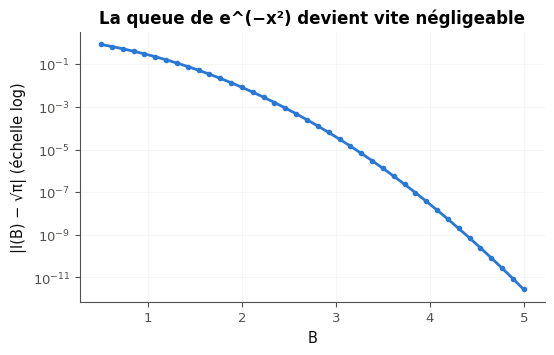

In [33]:
Bs = np.linspace(0.5, 5, 40)
gaps = [max(abs(I(B) - gauss), 1e-17) for B in Bs]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.semilogy(Bs, gaps, marker=".")
ax.set_xlabel("B")
ax.set_ylabel("|I(B) − √π| (échelle log)")
ax.set_title("La queue de e^(−x²) devient vite négligeable")
ax.grid(True, which="both", alpha=0.3)
plt.show()

💡 L'écart vaut environ 0,28 pour $B = 1$, $8 \times 10^{-3}$ pour $B = 2$, $4 \times 10^{-5}$ pour $B = 3$, $3 \times 10^{-8}$ pour $B = 4$ : il s'effondre plus vite qu'une exponentielle (la courbe en échelle log plonge de plus en plus vite). La borne : $\sqrt{\pi} - I(B) \le 2\int_B^{+\infty} e^{-Bx}\,dx = \frac{2e^{-B^2}}{B}$, soit environ $5 \times 10^{-8}$ pour $B = 4$. Pour la densité normale, la masse au-delà de 6 écarts types vaut environ $2 \times 10^{-9}$ : couper à 6 ne change rien en pratique.

### Ex M02a.22 — L'aire qui se remplit : la courbe, les rectangles et la primitive 🎨 ★ ⏱️ 20 min
**Objectif :** dessiner une somme de Riemann, puis la fonction aire, et voir qu'elle coïncide avec une primitive.  
**Prérequis :** fiche §1 et §2 ; R0 (matplotlib) · **Parcours :** C, E

Complète deux fonctions, qui dessinent dans l'axe `ax` qu'elles reçoivent :
- `draw_riemann(ax, f, a, b, n)` : la courbe de $f$ sur $[a ; b]$ (`ax.plot`), les $n$ rectangles **au milieu** (`ax.bar(lefts, heights, width=h, align="edge", alpha=0.4)`, où `lefts` sont les abscisses $a + ih$ des bords gauches) et, dans le titre, la somme des aires des rectangles avec 4 décimales (`f"somme = {total:.4f}"`) ;
- `draw_area_function(ax, f, F, a, b)` : sur une grille de 200 points de $[a ; b]$, deux courbes : la **fonction aire** $A(x) = \int_a^x f$, calculée numériquement (méthode des trapèzes cumulée : `np.cumsum`), et $F(x) - F(a)$, calculée avec la primitive `F` ; avec une légende.

⚠️ `f` et `F` prennent **un** nombre (elles sont écrites avec `math`) : sur une grille `xs`, calcule `ys = np.array([f(x) for x in xs])`, pas `f(xs)`.

La cellule suivante les essaie sur $f(x) = 1 + x\,e^{-x}$ entre 0 et 4 (une primitive est $F(x) = x - (x + 1)e^{-x}$, par parties) ; une autre les vérifie sur une autre fonction.

Dans ta copie : les deux courbes de droite se superposent-elles ? Quel théorème cela illustre-t-il ? Où la fonction aire monte-t-elle le plus vite, et pourquoi là ?

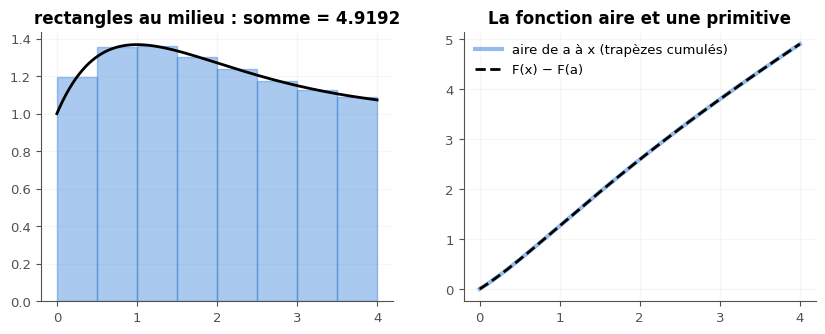

In [34]:
def draw_riemann(ax, f, a, b, n):
    """Draw f on [a, b], its n midpoint rectangles (ax.bar) and their total area in the title (4 decimals)."""
    h = (b - a) / n
    lefts = [a + i * h for i in range(n)]
    heights = [f(left + h / 2) for left in lefts]
    xs = np.linspace(a, b, 300)
    ax.bar(lefts, heights, width=h, align="edge", alpha=0.4, edgecolor="C0")
    ax.plot(xs, [f(x) for x in xs], color="black")
    ax.set_title(f"rectangles au milieu : somme = {h * sum(heights):.4f}")
    ax.grid(True, alpha=0.3)


def draw_area_function(ax, f, F, a, b):
    """Draw the area function x -> ∫_a^x f (cumulative trapezoids) and F(x) − F(a) on 200 points of [a, b]."""
    xs = np.linspace(a, b, 200)
    ys = np.array([f(x) for x in xs])
    pieces = (xs[1:] - xs[:-1]) * (ys[1:] + ys[:-1]) / 2       # the area of each trapezoid
    area = np.concatenate([[0.0], np.cumsum(pieces)])
    ax.plot(xs, area, linewidth=3, alpha=0.5, label="aire de a à x (trapèzes cumulés)")
    ax.plot(xs, [F(x) - F(a) for x in xs], "--", color="black", label="F(x) − F(a)")
    ax.set_title("La fonction aire et une primitive")
    ax.legend()
    ax.grid(True, alpha=0.3)


f_demo = lambda x: 1 + x * math.exp(-x)              # noqa: E731
F_demo = lambda x: x - (x + 1) * math.exp(-x)        # noqa: E731
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
draw_riemann(ax1, f_demo, 0, 4, 8)
draw_area_function(ax2, f_demo, F_demo, 0, 4)
plt.show()

**Vérifications automatiques** (les figures elles-mêmes se jugent à l'œil).

In [35]:
with checked("M02a.22 vérifications"):
    problems = []
    f_test, F_test = (lambda x: math.cos(x) + 1.5), (lambda x: math.sin(x) + 1.5 * x + 2)   # F(0) = 2, not 0
    fig, ax = plt.subplots(figsize=(5, 3))
    try:
        created = drawn(draw_riemann, ax, f_test, 0, 3, 6)
    finally:
        plt.close(fig)                                   # only the checks below are shown here
    if created:
        problems.append("draw_riemann ouvre sa propre figure : dessine dans l'axe reçu (ax.bar, ax.plot)")
    else:
        bars = [p for p in ax.patches if hasattr(p, "get_width")]
        mids = [0.25 + 0.5 * i for i in range(6)]
        if len(bars) != 6:
            problems.append(f"draw_riemann : n = 6 rectangles avec ax.bar (j'en compte {len(bars)})")
        else:
            widths = sorted(round(b.get_width(), 6) for b in bars)
            heights = sorted(round(b.get_height(), 6) for b in bars)
            lefts = sorted(round(b.get_x(), 6) for b in bars)
            if widths != [0.5] * 6 or lefts != [0.5 * i for i in range(6)]:
                problems.append("draw_riemann : des rectangles de largeur h = (b − a)/n, qui partent de a + i h "
                                "(ax.bar(..., width=h, align=\"edge\"))")
            elif heights != sorted(round(f_test(m), 6) for m in mids):
                problems.append("draw_riemann : la hauteur de chaque rectangle est f au milieu de son intervalle")
        if not ax.lines:
            problems.append("draw_riemann : la courbe de f, avec ax.plot")
        total = 0.5 * sum(f_test(m) for m in mids)
        if f"{total:.4f}" not in ax.get_title().replace(",", "."):
            problems.append("draw_riemann : la somme des aires des rectangles dans le titre, avec 4 décimales")
    fig, ax = plt.subplots(figsize=(5, 3))
    try:
        created = drawn(draw_area_function, ax, f_test, F_test, 0, 3)
    finally:
        plt.close(fig)
    if created:
        problems.append("draw_area_function ouvre sa propre figure : dessine dans l'axe reçu")
    else:
        exact = F_test(3) - F_test(0)
        curves = [line for line in ax.lines if len(np.atleast_1d(line.get_ydata())) >= 50]
        good = [line for line in curves if abs(float(np.atleast_1d(line.get_ydata())[0])) < 1e-9
                and abs(float(np.atleast_1d(line.get_ydata())[-1]) - exact) < 1e-3]
        if len(curves) < 2:
            problems.append("draw_area_function : deux courbes sur la grille de 200 points, l'aire calculée et "
                            "F(x) − F(a)")
        elif len(good) < 2:
            problems.append("draw_area_function : les deux courbes partent de 0 en x = a (une aire de a à a) et "
                            "finissent à F(b) − F(a), l'intégrale de a à b : trace F(x) − F(a), pas F(x)")
    if problems:
        print("❌ Ex M02a.22 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex M02a.22 : les rectangles, leur somme, et la fonction aire qui suit F(x) − F(a).")

✅ Ex M02a.22 : les rectangles, leur somme, et la fonction aire qui suit F(x) − F(a).


💡 Les deux courbes de droite se superposent : la fonction aire est une primitive de $f$ (théorème fondamental, §2). Elle monte le plus vite là où $f$ est la plus haute, vers $x = 1$ (le maximum de $1 + x\,e^{-x}$) : sa pente est $f(x)$.

## Partie C · Erreurs classiques, vérification et défi

Fiche §1, §2, §3 et §5. Trois erreurs à trouver, une primitive vérifiée par SymPy, puis le défi des dix évaluations.

### Ex M02a.23 — Chasse à l'erreur : bornes inversées, primitive fausse, aire négative 🐛 ★ ⏱️ 15 min
**Objectif :** repérer trois erreurs classiques du calcul intégral, puis calculer les bonnes valeurs.  
**Prérequis :** fiche §1 et §2 · **Parcours :** C

Voici cinq calculs, chacun avec ce qu'en dit son auteur. Trois sont faux. **Sans exécuter de code**, trouve-les.

- **(A)** « $\int_0^2 3x^2\,dx = \big[x^3\big]_2^0 = 0 - 8 = -8$. »
- **(B)** « Une primitive de $\frac{1}{x^2}$ est $-\frac{1}{x}$, donc $\int_1^2 \frac{dx}{x^2} = -\frac{1}{2} - (-1) = \frac{1}{2}$. »
- **(C)** « Une primitive de $e^{-3x}$ est $e^{-3x}$, donc $\int_0^1 e^{-3x}\,dx = e^{-3} - 1 \approx -0{,}9502$. »
- **(D)** « L'aire de la région comprise entre la courbe de $x^2 - 1$ et l'axe des abscisses, pour $x$ de 0 à 2, vaut $\int_0^2 (x^2 - 1)\,dx = \frac{8}{3} - 2 = \frac{2}{3}$. »
- **(E)** « $\int_1^e \frac{2}{x}\,dx = \big[2\ln x\big]_1^e = 2$. »

Questions :
- a) les lettres des calculs faux, dans l'ordre alphabétique (un texte) ;
- b) pour chacun des cinq, de (A) à (E), la bonne valeur de ce que décrit la phrase de son auteur (une liste de 5 nombres, 4 décimales).

Dans ta copie : pour chaque calcul faux, quelle règle a été oubliée ? Quel signe aurait dû alerter l'auteur de (C) ?

In [36]:
answer_M02a_23a = "ACD"
answer_M02a_23b = [8, 0.5, (1 - math.exp(-3)) / 3, 2, 2]
print(answer_M02a_23a, [round(v, 4) for v in answer_M02a_23b])
x = sp.Symbol("x")
print(sp.integrate(3 * x ** 2, (x, 0, 2)), sp.integrate(1 / x ** 2, (x, 1, 2)), sp.integrate(sp.exp(-3 * x), (x, 0, 1)),
      -sp.integrate(x ** 2 - 1, (x, 0, 1)) + sp.integrate(x ** 2 - 1, (x, 1, 2)), sp.integrate(2 / x, (x, 1, sp.E)))

ACD [8, 0.5, 0.3167, 2, 2]
8 1/2 1/3 - exp(-3)/3 2 2


In [37]:
wbm.record("M02a.23a", "ACD",
           mistakes={"il manque une ligne fautive : relis l'ordre des bornes dans chaque crochet [F(x)] : la borne du haut d'abord": "CD",
                     "il manque une ligne fautive : dérive chaque primitive annoncée : redonne-t-elle la fonction ? Une fonction positive a une intégrale positive": "AD",
                     "il manque une ligne fautive : relis chaque phrase qui parle d'aire : l'intégrale compte négativement ce qui est sous l'axe": "AC",
                     "une ligne de trop : la ligne (B) est correcte ; relis ce qu'elle fait": "ABCD",
                     "une ligne de trop : la ligne (E) est correcte ; relis ce qu'elle fait": "ACDE",
                     "la ligne (B) est correcte, et il manque une ligne fautive : relis l'ordre des bornes dans chaque crochet [F(x)] : la borne du haut d'abord": "BCD",
                     "la ligne (E) est correcte, et il manque une ligne fautive : relis l'ordre des bornes dans chaque crochet [F(x)] : la borne du haut d'abord": "CDE",
                     "la ligne (B) est correcte, et il manque une ligne fautive : dérive chaque primitive annoncée : redonne-t-elle la fonction ? Une fonction positive a une intégrale positive": "ABD",
                     "la ligne (E) est correcte, et il manque une ligne fautive : dérive chaque primitive annoncée : redonne-t-elle la fonction ? Une fonction positive a une intégrale positive": "ADE",
                     "la ligne (B) est correcte, et il manque une ligne fautive : relis chaque phrase qui parle d'aire : l'intégrale compte négativement ce qui est sous l'axe": "ABC",
                     "la ligne (E) est correcte, et il manque une ligne fautive : relis chaque phrase qui parle d'aire : l'intégrale compte négativement ce qui est sous l'axe": "ACE",
                     "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple": {"A", "C", "D"},
                     "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple": {"B", "E", "AB", "AE", "BC", "BD", "BE", "CE", "DE", "ABE", "BCE", "BDE", "ABCE", "ABDE", "BCDE"},
                     "plusieurs lignes que tu cites sont correctes : vérifie chacune avec un petit exemple": {"ABCDE"}})
wbm.record("M02a.23b", [8.0, 0.5, (1 - math.exp(-3)) / 3, 2.0, 2.0], decimals=4,
           mistakes={"ce sont les valeurs que donnent les calculs ; donne celles que décrit chaque phrase":
                         [-8.0, 0.5, math.exp(-3) - 1, 2 / 3, 2.0],
                     "(D) demande une aire : la partie sous l'axe compte positivement":
                         [8.0, 0.5, (1 - math.exp(-3)) / 3, 2 / 3, 2.0]})

WBM_ANSWER {"hash": "03536e18a86cd1c616007675d48f11426656cad41feb5b15350e3d2641454c65", "id": "M02a.23a", "kind": "str", "mistakes": {"0c08676825d0f65f3e881376f34591de2c8ba049ad9cd2a4c16061d1a3917ac9": "la ligne (B) est correcte, et il manque une ligne fautive : relis chaque phrase qui parle d'aire : l'intégrale compte négativement ce qui est sous l'axe", "0cd253036f3108a1a6ba3b58f8aff4c51b93aad922b17932953c09c7de2e0f86": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "14d79474a25a800a4897a44885b53f1b135d479ea38f09ef6deb4588b6b6d96b": "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple", "23232e93f9c3c9cf3c32581cb8ed2f87bf5b653a39af72f295629956f0ecfa80": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "2ee025394ababc6ba3d1c6f3d8c5d172142857ff8c8dc6c958b8178285614fb9": "il manque une ligne fautive : relis chaqu

💡 (A) Les bornes sont inversées dans le crochet : $\big[x^3\big]_0^2 = 8$. (C) La primitive est fausse : la dérivée de $e^{-3x}$ vaut $-3e^{-3x}$ ; une primitive de $e^{-3x}$ est $-\frac{1}{3}e^{-3x}$, d'où $\frac{1 - e^{-3}}{3} \approx 0{,}3167$. Le signe négatif devait alerter : une fonction positive a une intégrale positive. (D) $x^2 - 1$ est négative sur $[0 ; 1[$ : l'aire vaut $\frac{2}{3} + \frac{4}{3} = 2$, alors que l'intégrale vaut $\frac{2}{3}$. (B) et (E) sont justes.

### Ex M02a.24 — Vérifier une primitive avec SymPy : dériver le résultat 🛠️ ★ ⏱️ 10 min
**Objectif :** écrire une petite fonction qui vérifie une primitive en la dérivant, réflexe professionnel avant d'utiliser un résultat.  
**Prérequis :** fiche §2 · **Parcours :** C

Une primitive se vérifie toujours en la **dérivant** : c'est plus sûr que de la recalculer, et cela marche quelle que soit sa forme. Écris `is_primitive(F, f)`, qui reçoit deux expressions SymPy en `x` et renvoie `True` si $F' = f$, `False` sinon. Outils : `sp.diff(F, x)` dérive, `sp.simplify(expression)` simplifie ; teste si la simplification de $F' - f$ vaut 0, et renvoie un booléen de Python (`bool(...)`).

⚠️ Ne compare pas $F'$ et $f$ avec `==` sans simplifier : SymPy compare alors l'**écriture** des expressions, pas leurs valeurs, et $\sin x \cos x$ n'est pas écrit comme la dérivée de $-\frac{\cos(2x)}{4}$.

Dans ta copie : `sin²x/2` et `−cos(2x)/4` sont toutes deux des primitives de $\sin x \cos x$. Que vaut leur différence ? Est-ce une contradiction ?

In [38]:
x = sp.Symbol("x")

In [39]:
def is_primitive(F, f):
    """True when the SymPy expression F is an antiderivative of f in x (F' − f simplifies to 0)."""
    return bool(sp.simplify(sp.diff(F, x) - f) == 0)


print(is_primitive(-sp.cos(2 * x) / 4, sp.sin(x) * sp.cos(x)), sp.diff(-sp.cos(2 * x) / 4, x) == sp.sin(x) * sp.cos(x),
      sp.simplify(sp.sin(x) ** 2 / 2 - (-sp.cos(2 * x) / 4)))

True False 1/4


In [40]:
with checked("M02a.24 vérifications"):
    problems = []
    cases = [
        (sp.sin(x) ** 2 / 2, sp.sin(x) * sp.cos(x), True, "sin²x/2 est une primitive de sin x cos x"),
        (-sp.cos(2 * x) / 4, sp.sin(x) * sp.cos(x), True, "−cos(2x)/4 aussi (elle diffère de la précédente d'une "
                                                         "constante)"),
        (sp.exp(x ** 2), sp.exp(x ** 2), False, "e^(x²) n'est pas une primitive de e^(x²) (règle de la chaîne)"),
        (sp.atan(x), 1 / (1 + x ** 2), True, "arctan est une primitive de 1/(1 + x²)"),
        (x * sp.exp(x), x * sp.exp(x), False, "x eˣ n'est pas une primitive de x eˣ"),
    ]
    for F_case, f_case, expected, why in cases:
        result = is_primitive(F_case, f_case)
        if result is None:
            problems.append("is_primitive ne renvoie rien (None) : il manque un return")
            break
        if not isinstance(result, bool):
            problems.append(f"is_primitive doit renvoyer un booléen de Python, True ou False, et non un objet de type "
                            f"{type(result).__name__} : convertis avec bool(...)")
            break
        if result is not expected:
            problems.append(f"is_primitive se trompe : {why}")
    if problems:
        print("❌ Ex M02a.24 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex M02a.24 : is_primitive reconnaît une primitive, même écrite sous une autre forme.")

✅ Ex M02a.24 : is_primitive reconnaît une primitive, même écrite sous une autre forme.


💡 $\frac{\sin^2 x}{2} - \left(-\frac{\cos 2x}{4}\right) = \frac{1}{4}$, une constante (car $\cos 2x = 1 - 2\sin^2 x$) : deux primitives d'une même fonction diffèrent d'une constante, pas de contradiction. La comparaison directe avec `==` rend `False`, alors que la primitive est juste : c'est le piège que `sp.simplify` évite.

### Ex M02a.25 — Défi : la meilleure précision avec dix évaluations de la fonction 🏆 ★★★ ⏱️ 30 min
**Objectif :** calculer trois intégrales à $10^{-8}$ près en n'évaluant chaque fonction que dix fois au plus.  
**Prérequis :** fiche §3 et §5 ; Ex M02a.16 et M02a.17 · **Parcours :** C

Écris `best_integral(f, a, b)`, qui approche $\int_a^b f$ en appelant `f` **au plus 10 fois**. **Objectif** : une erreur inférieure à $10^{-8}$ sur chacune des trois intégrales de la cellule fournie (comparées à `quad`, très précis). La cellule de vérification compte les appels.

Simpson avec 8 intervalles (9 évaluations) donne des erreurs de l'ordre de $10^{-5}$ : loin du compte. Il faut une idée de plus. Pistes, de la plus simple à la plus efficace (`04_indices.md` les détaille) :
1. combiner deux résultats de Simpson, avec 4 et 8 intervalles, pour annuler le terme d'erreur principal (tous les points de l'un sont parmi ceux de l'autre) ;
2. renoncer aux points régulièrement espacés : il existe des points et des poids **choisis** pour être exacts sur des polynômes de degré bien plus élevé (cherche « quadrature de Gauss-Legendre » ; `np.polynomial.legendre.leggauss(n)` donne ces points et ces poids sur $[-1 ; 1]$, à ramener sur $[a ; b]$ par un changement de variable affine, §3).

Dans ta copie : quelle meilleure erreur obtiens-tu sur chaque intégrale, avec quelle méthode ? Pourquoi la troisième est-elle la plus difficile pour les méthodes à points réguliers ?

In [41]:
CHALLENGE = [
    ("e^(−x²) sur [0 ; 2]", lambda x: math.exp(-x ** 2), 0, 2),
    ("1/(1 + x) sur [0 ; 1]", lambda x: 1 / (1 + x), 0, 1),
    ("√(1 + x³) sur [0 ; 2]", lambda x: math.sqrt(1 + x ** 3), 0, 2),
]
TARGET = 1e-8


def counted(f):
    """f, with a counter of its calls (counted_f.calls)."""
    def wrapper(x):
        wrapper.calls += 1
        return f(x)
    wrapper.calls = 0
    return wrapper

In [42]:
def best_integral(f, a, b):
    """Approximate ∫_a^b f with at most 10 calls of f: Gauss-Legendre quadrature with 10 points."""
    nodes, weights = np.polynomial.legendre.leggauss(10)        # exact for polynomials of degree up to 19 on [-1, 1]
    half, middle = (b - a) / 2, (a + b) / 2                      # x = middle + half t maps [-1, 1] onto [a, b]
    return float(half * sum(w * f(middle + half * t) for t, w in zip(nodes, weights)))


worst = 0.0
for name, f, a, b in CHALLENGE:
    g = counted(f)
    value = best_integral(g, a, b)
    error = abs(value - quad(f, a, b, epsabs=1e-13, epsrel=1e-13)[0])
    worst = max(worst, error)
    print(f"{name:24} erreur : {error:.1e}   évaluations : {g.calls}")
print("objectif atteint :", worst < TARGET)

e^(−x²) sur [0 ; 2]      erreur : 3.1e-13   évaluations : 10
1/(1 + x) sur [0 ; 1]    erreur : 6.7e-16   évaluations : 10
√(1 + x³) sur [0 ; 2]    erreur : 1.7e-09   évaluations : 10
objectif atteint : True


In [43]:
wbm.record("M02a.25", True,
           mistakes={"l'objectif n'est pas atteint : relis les pistes de l'énoncé et de 04_indices.md": False})

WBM_ANSWER {"hash": "eeea346cbc86bc69935ada18aba6f446867bd5a5468a8898c25590458be33ca4", "id": "M02a.25", "kind": "bool", "mistakes": {"416cf4ee40b7e10306da5aba3b4aea4b018ff22d2105083dd894cb9cb18f7c41": "l'objectif n'est pas atteint : relis les pistes de l'énoncé et de 04_indices.md"}}
📝 Ex M02a.25 : réponse enregistrée (bool).


💡 Avec 10 points de Gauss-Legendre, les erreurs tombent à $3 \times 10^{-13}$, $10^{-15}$ et $2 \times 10^{-9}$. La combinaison $\frac{16 S_8 - S_4}{15}$ (piste 1, la méthode de Boole) donne environ $10^{-6}$ sur les deux premières, mais $4 \times 10^{-5}$ sur la troisième. Les points de Gauss sont choisis pour que la formule soit exacte sur les polynômes de degré au plus 19 : avec le même nombre d'évaluations, c'est bien mieux que Simpson (degré 3). La troisième fonction, $\sqrt{1 + x^3}$, a des dérivées d'ordre 4 et plus qui grandissent vite sur $[0 ; 2]$ : c'est elle qui limite les méthodes de Newton-Cotes (rectangles, trapèzes, Simpson, Boole).

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Calcules-tu une intégrale avec une primitive, et sais-tu la distinguer d'une aire géométrique ?
2. Sais-tu programmer les rectangles, les trapèzes et Simpson, et prévoir leur erreur ?
3. Passes-tu d'une densité à des probabilités, à la fonction de répartition et aux quantiles ?

**La suite** : M02b, les variables aléatoires et les lois usuelles, puis M02c, avant le chapitre 2 de workbookIA.